# Building Age Classification from Satellite Imagery

# Notebook 8 -Full Pipeline & Final Model: EDA → Feature Engineering → Model Exploration → Final Transfer Model

---

This notebook is **self-contained**: it reads only the two parquet files in `data/` and does not need Notebooks2-7(as they were model testing notebooks to find best ideas), or any cache. It is our complete submission notebook.

| Part | What we do | Why |
|---|---|---|
| **A. EDA** | Data structure, data quality, labels, spectra, sensors, seasons, spatial structure | Find out *why* a Madrid model fails in Amsterdam and what signal transfers between cities |
| **B. Feature engineering** | Season filter, city-year anomaly, change-point (construction event) features, neighbourhood context; checked with an adversarial domain test | Features that mean the same thing in every city |
| **C. Stage 1 (Madrid)** | Spatial cross-validation and a model zoo (LightGBM, Random Forest, CatBoost, Extra Trees) plus an ensemble | Which model learns the most *transferable* knowledge |
| **D. Stage 2 (Amsterdam)** | A step-by-step ablation ladder: continued boosting → spatial smoothing → capacity scaling → **self-training on unlabelled pixels** → spatial label propagation | Every step is kept only if it improves held-out Amsterdam F1 |
| **E. Results** | Final table (mean ± std), F1 vs log2(n) plot, confusion matrices, per-class F1, reusable `adapt_to_city(n)` | The submission deliverables |

### Scoring (from Notebook 1)

| Prize | Metric |
|---|---|
| Best average F1 | Mean macro-F1 over the five Amsterdam models (n = 5, 25, 50, 100, 200 per class) |
| Best peak F1 | Highest macro-F1 of any single Amsterdam model |
| Best low-data F1 | Macro-F1 of the **n = 25** model |
| Best originality | Abstract + presentation |

### Reference points

| Setting | Notebook 4 baseline | Notebook 5 (our first model) |
|---|:-:|:-:|
| Amsterdam zero-shot | 0.343 | 0.530 |
| n = 5 / 25 / 50 / 100 / 200 | 0.544 / 0.599 / 0.608 / 0.613 / 0.615 | 0.557 / 0.650 / 0.680 / 0.714 / 0.731 |
| Average | 0.596 | 0.666 |

## 7.1 Setup

All settings are in the config cell. `SEED` fixes every random draw.

Put the two parquet files in a `data/` folder next to this notebook (or one level up). The notebook streams the parquet files in batches, so peak memory stays around 2-3 GB. Cubes and feature tables are cached in `data/cache/` with an `nb7_` prefix, so a re-run after a kernel restart skips the slow steps.

**Run time**. The slow parts are the Stage 1 model zoo (`STAGE1_MODELS`) and the ablation ladder (`RUN_ABLATION`). Set `QUICK = True` for a smoke test of a few minutes.

In [1]:
import gc
import json
import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import lightgbm as lgb
from scipy.ndimage import uniform_filter
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import f1_score, confusion_matrix, roc_auc_score, accuracy_score, balanced_accuracy_score

try:
    from catboost import CatBoostClassifier          # optional:  pip install catboost
except ImportError:
    CatBoostClassifier = None
try:
    import torch                                     # optional:  pip install torch  (prototypical network, 7.19b)
except ImportError:
    torch = None

warnings.filterwarnings('ignore', category=RuntimeWarning)   # all-NaN medians are expected
warnings.filterwarnings('ignore', message='X does not have valid feature names')
plt.rcParams['figure.dpi'] = 100

# ── Config ────────────────────────────────────────────────────────────────────
SEED          = 42
SHOTS         = [5, 25, 50, 100, 200]          # labelled Amsterdam pixels per class
N_TRIALS      = 10                             # random support draws per shot size (final results)
ABL_TRIALS    = 5                              # development draws per shot size (ablation ladder + tournament)
N_FOLDS       = 5                              # Madrid cross-validation folds
N_JOBS        = min(os.cpu_count() or 4, 16)   # CPU threads (uses the whole VM)
DOY_WINDOW    = (121, 273)                     # keep observations from 1 May to 30 Sep (section 7.5)
STAGE1_MODELS = ['lgbm', 'rf', 'cat', 'et']    # model zoo for section 7.16 (drop some for speed)
RUN_ABLATION  = True                           # run the Stage 2 ablation ladder (section 7.18)
RUN_SEASON_ABLATION = True                     # also build the no-season-filter features to compare
RUN_IMPORTANCE = True                          # group-drop ablation in section 7.23 (6 LightGBM refits)
RUN_TOURNAMENT = True                          # idea tournament + per-n selection in section 7.20
RUN_PROTONET  = True                           # classic few-shot baseline: prototypical network (7.19b, needs torch)
QUICK         = False                      # True = few draws and small zoo, only to smoke-test

if QUICK:
    N_TRIALS, ABL_TRIALS, N_FOLDS, STAGE1_MODELS, RUN_SEASON_ABLATION = 2, 1, 3, ['lgbm', 'rf'], False   # every section still runs

# ── Paths: works from the repo root or a subfolder ───────────────────────────
DATA_DIR  = next(p for p in [Path('data'), Path('../data')] if (p / 'madrid_train.parquet').exists())
CACHE_DIR = DATA_DIR / 'cache';  CACHE_DIR.mkdir(exist_ok=True)
MODEL_DIR = Path('models');      MODEL_DIR.mkdir(exist_ok=True)
RESULTS_DIR = Path('results');   RESULTS_DIR.mkdir(exist_ok=True)   # final tables, figures and nb7_summary.json
FILES     = {'Madrid': 'madrid_train.parquet', 'Amsterdam': 'amsterdam_data.parquet'}

# ── Domain constants ──────────────────────────────────────────────────────────
BANDS        = ['Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2']
INDICES      = ['NDVI', 'NDBI', 'UI', 'MNDWI', 'BSI']
CHANNELS     = BANDS + INDICES
YEARS        = np.arange(1984, 2026)           # 42 annual time steps
BLUE_MAX     = 15_000                          # haze threshold (Notebook 2)
CLASS_EVENTS = {'Amsterdam': 1945, 'Madrid': 1960}
CLASS_COLORS = {1: '#4393c3', 2: '#2ca25f', 3: '#fd8d3c', 4: '#de2d26'}
CITY_COLORS  = {'Madrid': '#d95f02', 'Amsterdam': '#1b9e77'}
CITIES       = ['Madrid', 'Amsterdam']
BASELINE     = {'zero-shot': 0.343, 5: 0.544, 25: 0.599, 50: 0.608, 100: 0.613, 200: 0.615}
NB5          = {'zero-shot': 0.530, 5: 0.557, 25: 0.650, 50: 0.680, 100: 0.714, 200: 0.731}
EARLIER      = {'zero-shot': 0.559, 5: 0.613, 25: 0.688, 50: 0.704, 100: 0.731, 200: 0.746}   # earlier internal model (LGBM+RF, smoothing, self-training)

print('Data folder:', DATA_DIR.resolve())
print('CatBoost available:', CatBoostClassifier is not None, '| torch available:', torch is not None)

Data folder: /home/participant-d5/Building_Age_Classification/data
CatBoost available: True | torch available: True


---
# Part A-Exploratory Data Analysis

## 7.2 What is in the files?

We read only the parquet **metadata** first (no data), so this is instant even on a small machine.

In [2]:
for city, f in FILES.items():
    pf = pq.ParquetFile(DATA_DIR / f)
    print(f'{city:10s} {f:25s} {pf.metadata.num_rows:>10,} rows  {pf.metadata.num_columns} columns  '
          f'{(DATA_DIR / f).stat().st_size / 1e6:.0f} MB on disk')
schema = pq.ParquetFile(DATA_DIR / FILES['Amsterdam']).schema_arrow
print('\nColumns:', ', '.join(schema.names))

Madrid     madrid_train.parquet       3,172,765 rows  48 columns  142 MB on disk
Amsterdam  amsterdam_data.parquet     1,062,877 rows  48 columns  44 MB on disk

Columns: pixel_id, city, year, px_key, py_key, pixel_x, pixel_y, row, col, coverage, usable_label, weighted_mean_year, Blue_1, Green_1, Red_1, NIR_1, SWIR1_1, SWIR2_1, QA_PIXEL_1, QA_RADSAT_1, doy_1, scene_id_1, dataset_1, qa_valid_1, Blue_2, Green_2, Red_2, NIR_2, SWIR1_2, SWIR2_2, QA_PIXEL_2, QA_RADSAT_2, doy_2, scene_id_2, dataset_2, qa_valid_2, Blue_3, Green_3, Red_3, NIR_3, SWIR1_3, SWIR2_3, QA_PIXEL_3, QA_RADSAT_3, doy_3, scene_id_3, dataset_3, qa_valid_3


**Layout.** One row = one 30 m pixel in one year (1984–2025). Each row holds up to **3 observations** (`_1`, `_2`, `_3`, sorted by day of year) with 6 bands, QA flags, the acquisition day of year (`doy_N`), the scene id and the sensor (`dataset_N`). The pixel-level label is `weighted_mean_year` (area-weighted construction year); `coverage` is the building fraction of the pixel.

## 7.3 Data quality: valid observations, seasons and sensors

We load only the small columns we need for this check (day of year, QA flag, sensor). The sensor column is read as a dictionary-encoded category, so it costs almost no memory.

Madrid     obs QA-valid: 93.6% | pixel-years with >=1 valid obs: 100.0% | with >=1 valid obs inside (121, 273): 97.1%
Amsterdam  obs QA-valid: 72.6% | pixel-years with >=1 valid obs: 100.0% | with >=1 valid obs inside (121, 273): 91.5%


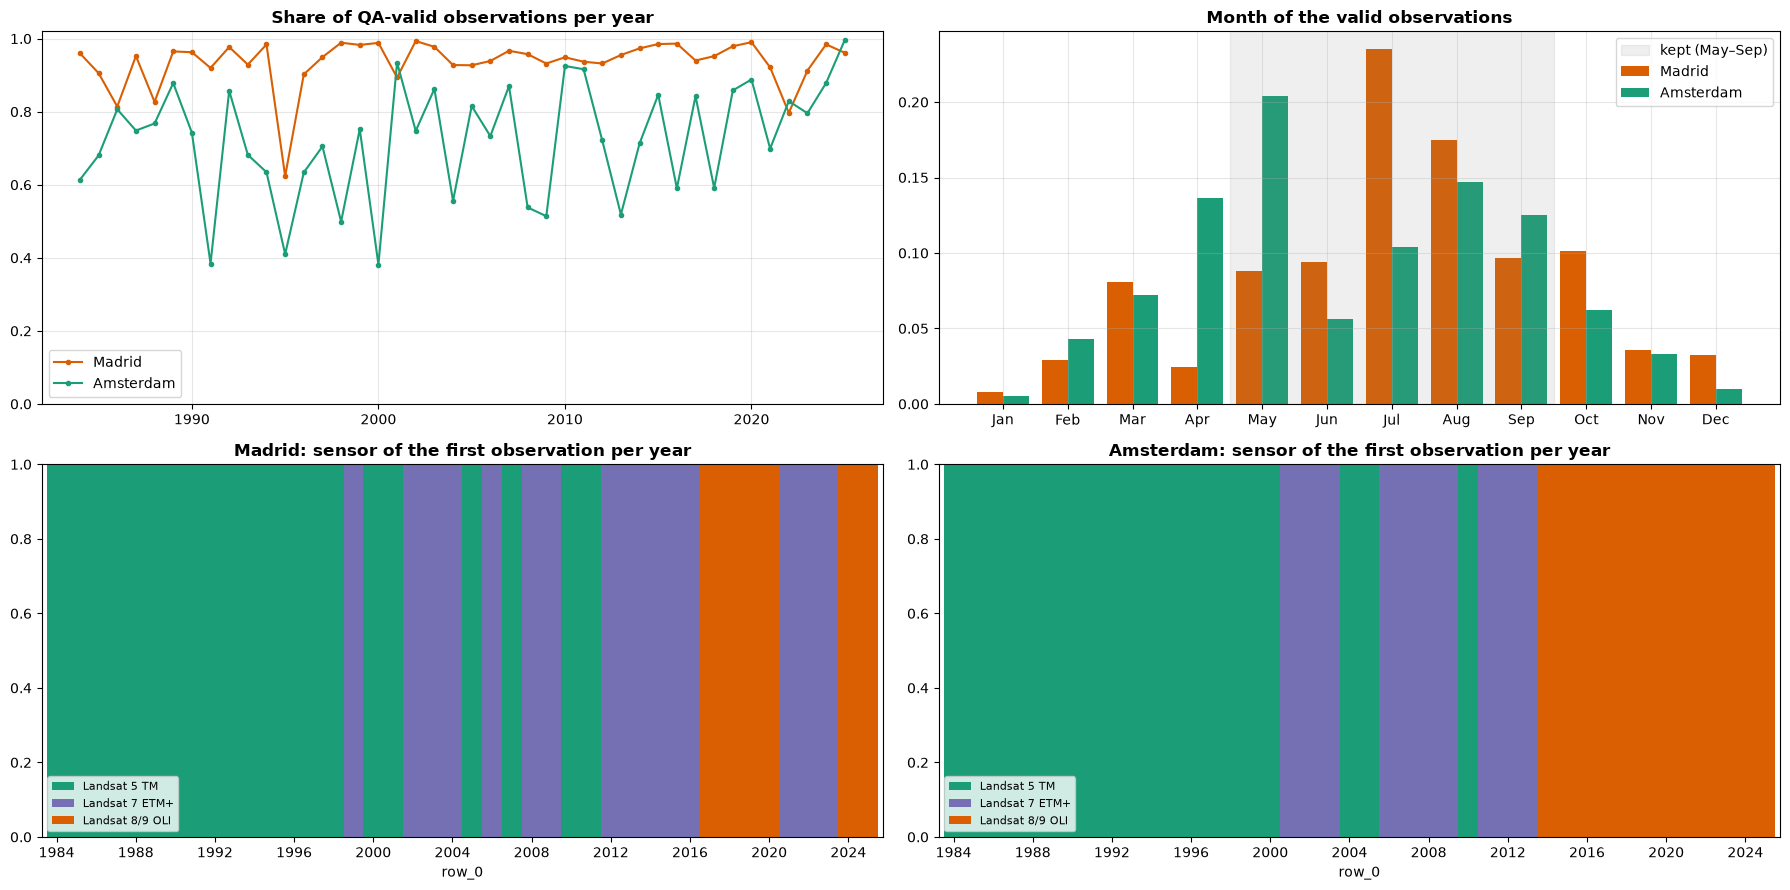

Years with no in-season observation for most pixels (filled by interpolation): {'Madrid': [1997], 'Amsterdam': [1990, 2011]}


In [3]:
MONTHS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
MONTH_EDGES = np.cumsum([0, 31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]) + 0.5
SENSOR_NAMES = {'landsat_tm_c2_l2': 'Landsat 5 TM', 'landsat_etm_c2_l2': 'Landsat 7 ETM+',
                'landsat_ot_c2_l2': 'Landsat 8/9 OLI'}

QA = {}
for city in CITIES:
    cols = ['year'] + [f'{k}_{s}' for s in (1, 2, 3) for k in ('doy', 'qa_valid')] + ['dataset_1']
    t = pq.read_table(DATA_DIR / FILES[city], columns=cols, read_dictionary=['dataset_1'])
    year = t['year'].to_numpy()
    valid = np.stack([np.nan_to_num(t[f'qa_valid_{s}'].to_numpy(zero_copy_only=False).astype(float)).astype(bool)
                      for s in (1, 2, 3)], 1)
    doy = np.stack([t[f'doy_{s}'].to_numpy(zero_copy_only=False).astype(float) for s in (1, 2, 3)], 1)
    in_season = valid & (doy >= DOY_WINDOW[0]) & (doy <= DOY_WINDOW[1])
    sensor = t['dataset_1'].to_pandas().astype(str).map(SENSOR_NAMES)
    QA[city] = dict(
        valid_rate=pd.Series(valid.mean(1), index=year).groupby(level=0).mean(),
        month_hist=np.histogram(doy[valid], bins=MONTH_EDGES)[0],
        any_valid=valid.any(1).mean(), any_in_season=in_season.any(1).mean(),
        season_by_year=pd.Series(in_season.any(1), index=year).groupby(level=0).mean(),
        sensor=pd.crosstab(year, sensor.values, normalize='index'))
    print(f'{city:10s} obs QA-valid: {valid.mean():.1%} | pixel-years with >=1 valid obs: {QA[city]["any_valid"]:.1%} '
          f'| with >=1 valid obs inside {DOY_WINDOW}: {QA[city]["any_in_season"]:.1%}')
    del t, valid, doy, in_season, sensor
gc.collect()

fig, axes = plt.subplots(2, 2, figsize=(18, 9))
for city in CITIES:
    QA[city]['valid_rate'].plot(ax=axes[0, 0], marker='o', ms=3, color=CITY_COLORS[city], label=city)
    h = QA[city]['month_hist']
    axes[0, 1].bar(np.arange(12) + (-.2 if city == 'Madrid' else .2), h / h.sum(), .4, color=CITY_COLORS[city], label=city)
axes[0, 0].set_title('Share of QA-valid observations per year', fontweight='bold'); axes[0, 0].set_ylim(0, 1.02)
axes[0, 1].set_xticks(range(12)); axes[0, 1].set_xticklabels(MONTHS)
axes[0, 1].axvspan(3.5, 8.5, color='grey', alpha=.12, label='kept (May–Sep)')
axes[0, 1].set_title('Month of the valid observations', fontweight='bold')
for ax, city in zip(axes[1], CITIES):
    QA[city]['sensor'].plot.bar(stacked=True, ax=ax, width=1, color=['#1b9e77', '#7570b3', '#d95f02'][:QA[city]['sensor'].shape[1]])
    ax.set_title(f'{city}: sensor of the first observation per year', fontweight='bold')
    ax.set_xticks(range(0, len(YEARS), 4)); ax.set_xticklabels(YEARS[::4], rotation=0); ax.legend(loc='lower left', fontsize=8)
for ax in axes[0]: ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

gaps = {city: QA[city]['season_by_year'][QA[city]['season_by_year'] < .5].index.tolist() for city in CITIES}
print('Years with no in-season observation for most pixels (filled by interpolation):', gaps)

**What the data-quality checks mean for the model**

* Only **93.6%** of Madrid observations and **72.6%** of Amsterdam observations pass QA. After restricting to 1 May-30 September, at least one usable scene remains for **97.1%** of Madrid pixel-years and **91.5%** of Amsterdam pixel-years. The broadest no-scene years are Madrid 1997 and Amsterdam 1990 and 2011; missing values are interpolated.
* Acquisition season, cloud cover, and sensor transitions can shift reflectance without any change in building age. Amsterdam has fewer clean scenes, so this noise is not balanced across cities.

**Decision and evidence:** keep QA-valid May-September observations, use the median when multiple scenes remain, and interpolate gaps. In the development ablation, this filter improves macro-F1 at every label budget by **0.004-0.009**. It is a reliable but modest gain, not the main source of the final improvement.

## 7.4 Loading the data into per-city cubes

For every pixel and year we combine the up-to-3 observations into **one value per band**:

1. Keep an observation only if it is QA-valid, has no zero or saturated band, passes the haze filter (Blue ≤ 15,000) and lies inside `DOY_WINDOW`.
2. Take the **median** of the surviving observations (Notebooks 2–4 used only the first one).

The loader **streams the file in batches** of 250,000 rows, so memory stays low even on a small VM. Each city becomes a dense `(pixels, years, bands)` array (the "cube").

In [4]:
def age_class(year, city):
    # Bin weighted_mean_year into classes 1-4 using the city-specific class-1/2 boundary.
    bins = [-np.inf, CLASS_EVENTS[city], 1984, 2004, np.inf]
    return pd.cut(year, bins=bins, labels=[1, 2, 3, 4]).astype(int)


def load_cube(city, doy_window=DOY_WINDOW, batch_rows=250_000):
    # Stream the parquet file in batches and pack it into a dense (pixels, years, bands) cube.
    #   cube[i, t, b]  median of the valid observations of pixel i in year YEARS[t] (NaN if none)
    #   n_obs[i, t]    number of valid observations behind that median (0-3)
    #   doy[i, t]      mean day-of-year of those observations
    # An observation is valid if QA-clear, no zero/saturated band, Blue <= BLUE_MAX (haze) and,
    # if doy_window is set, acquired inside that day-of-year window.
    tag = 'all' if doy_window is None else f'{doy_window[0]}-{doy_window[1]}'
    path = CACHE_DIR / f'nb7_cube_{city}_{tag}.npz'
    if path.exists():
        z = np.load(path)
        return {k: z[k] for k in z.files}

    pf = pq.ParquetFile(DATA_DIR / FILES[city])
    keys_tbl = pf.read(columns=['px_key', 'py_key'])
    ukeys = np.unique(keys_tbl['px_key'].to_numpy().astype(np.int64) * 1_000_000 + keys_tbl['py_key'].to_numpy())
    del keys_tbl
    n_pix, n_yr = len(ukeys), len(YEARS)
    cube = np.full((n_pix, n_yr, len(BANDS)), np.nan, np.float32)
    n_obs = np.zeros((n_pix, n_yr), np.int8)
    doy_c = np.full((n_pix, n_yr), np.nan, np.float32)
    const = {k: np.zeros(n_pix, dt) for k, dt in
             [('px', np.int32), ('py', np.int32), ('x', np.float64), ('y', np.float64),
              ('coverage', np.float32), ('wmy', np.float32)]}

    cols = ['year', 'px_key', 'py_key', 'pixel_x', 'pixel_y', 'coverage', 'weighted_mean_year']
    for s in (1, 2, 3):
        cols += [f'{b}_{s}' for b in BANDS] + [f'qa_valid_{s}', f'doy_{s}']
    for batch in pf.iter_batches(batch_size=batch_rows, columns=cols):
        col = lambda name: batch.column(name).to_numpy(zero_copy_only=False)
        px, py = col('px_key'), col('py_key')
        pix = np.searchsorted(ukeys, px.astype(np.int64) * 1_000_000 + py)
        yr = col('year') - YEARS[0]
        obs = np.stack([np.stack([col(f'{b}_{s}').astype(np.float32) for b in BANDS], 1) for s in (1, 2, 3)], 1)
        doy = np.stack([col(f'doy_{s}').astype(np.float32) for s in (1, 2, 3)], 1)
        valid = np.nan_to_num(np.stack([col(f'qa_valid_{s}').astype(float) for s in (1, 2, 3)], 1)).astype(bool)
        valid &= np.isfinite(obs).all(2) & (obs > 0).all(2) & (obs < 65535).all(2)
        valid &= obs[:, :, 0] <= BLUE_MAX
        if doy_window is not None:
            valid &= (doy >= doy_window[0]) & (doy <= doy_window[1])
        obs[~valid] = np.nan; doy[~valid] = np.nan
        cube[pix, yr] = np.nanmedian(obs, axis=1)
        n_obs[pix, yr] = valid.sum(1)
        doy_c[pix, yr] = np.nanmean(doy, axis=1)
        for k, name in [('px', 'px_key'), ('py', 'py_key'), ('x', 'pixel_x'), ('y', 'pixel_y'),
                        ('coverage', 'coverage'), ('wmy', 'weighted_mean_year')]:
            const[k][pix] = col(name)
        del batch, obs, doy, valid
    out = dict(cube=cube, n_obs=n_obs, doy=doy_c, **const)
    np.savez_compressed(path, **out)
    return out


t0 = time.time()
DATA = {city: load_cube(city) for city in CITIES}
Y    = {city: age_class(DATA[city]['wmy'], city) for city in CITIES}
print(f'Loaded in {time.time() - t0:.0f}s')
for city, d in DATA.items():
    print(f"{city:10s} cube {d['cube'].shape}  ({d['cube'].nbytes / 1e6:.0f} MB)  "
          f"class counts {np.bincount(Y[city])[1:].tolist()}  construction years {d['wmy'].min():.0f}-{d['wmy'].max():.0f}  "
          f"missing pixel-years {np.isnan(d['cube'][:, :, 0]).mean():.1%}")

Loaded in 1s
Madrid     cube (76263, 42, 6)  (77 MB)  class counts [13794, 27152, 18672, 16645]  construction years 1850-2021  missing pixel-years 4.8%
Amsterdam  cube (25992, 42, 6)  (26 MB)  class counts [7568, 8802, 6745, 2877]  construction years 1850-2016  missing pixel-years 11.4%


## 7.5 Labels: construction years and class balance

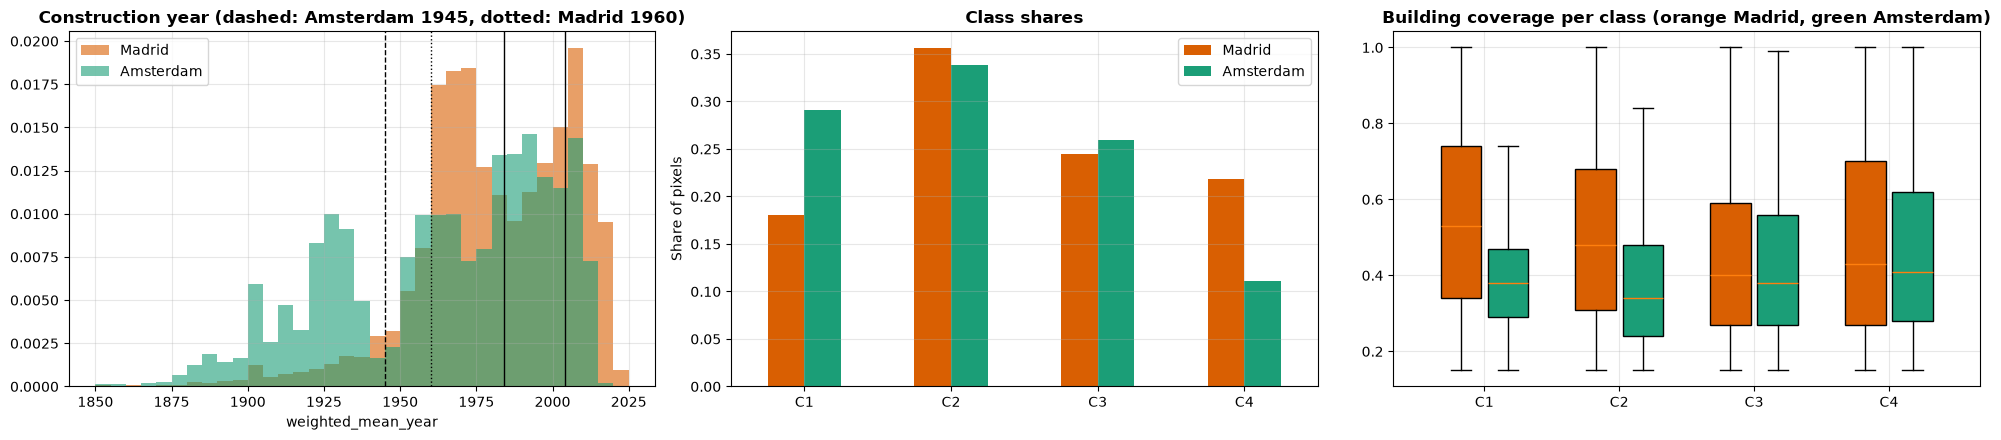

,Madrid,Amsterdam
Class 1,13794,7568
Class 2,27152,8802
Class 3,18672,6745
Class 4,16645,2877
Total,76263,25992


Newest building: Madrid 2021, Amsterdam 2016


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
for city, d in DATA.items():
    axes[0].hist(d['wmy'], bins=np.arange(1850, 2026, 5), alpha=.6, density=True, color=CITY_COLORS[city], label=city)
for b, ls in [(1945, '--'), (1960, ':'), (1984, '-'), (2004, '-')]:
    axes[0].axvline(b, color='k', ls=ls, lw=1)
axes[0].set_title('Construction year (dashed: Amsterdam 1945, dotted: Madrid 1960)', fontweight='bold')
axes[0].set_xlabel('weighted_mean_year'); axes[0].legend()

share = pd.DataFrame({city: np.bincount(Y[city])[1:] / len(Y[city]) for city in CITIES}, index=[f'C{k}' for k in range(1, 5)])
share.plot.bar(ax=axes[1], color=[CITY_COLORS[c] for c in CITIES], rot=0)
axes[1].set_title('Class shares', fontweight='bold'); axes[1].set_ylabel('Share of pixels')

for i, city in enumerate(CITIES):
    data = [DATA[city]['coverage'][Y[city] == k] for k in range(1, 5)]
    bp = axes[2].boxplot(data, positions=np.arange(1, 5) + (i - .5) * .35, widths=.3, showfliers=False, patch_artist=True)
    for patch in bp['boxes']: patch.set_facecolor(CITY_COLORS[city])
axes[2].set_xticks(range(1, 5)); axes[2].set_xticklabels([f'C{k}' for k in range(1, 5)])
axes[2].set_title('Building coverage per class (orange Madrid, green Amsterdam)', fontweight='bold')
for ax in axes: ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

counts = pd.DataFrame({city: np.bincount(Y[city])[1:] for city in CITIES}, index=[f'Class {k}' for k in range(1, 5)])
counts.loc['Total'] = counts.sum()
display(counts)
print(f"Newest building: Madrid {DATA['Madrid']['wmy'].max():.0f}, Amsterdam {DATA['Amsterdam']['wmy'].max():.0f}")

**What the label distributions imply**

* Both cities are **imbalanced**: class 4 (2004+) is the rarest, especially in Amsterdam (about 11%). Macro-F1 gives every era equal weight rather than letting common classes dominate.
* Amsterdam's newest building is from **2016**, so its class 4 covers 2004-2016; Madrid's extends later. The target city also places the class 1/2 boundary at 1945, versus 1960 in Madrid. These are genuine label-definition differences, not just model noise.
* Building coverage differs by class and city, another reason not to expect raw reflectance thresholds to transfer unchanged.

The later errors are consistent with these limits: class 4 remains hardest at low label counts, while class 1 versus class 2 is difficult because both are largely pre-satellite eras and the boundary is city-specific.

## 7.6 Amsterdam is darker in every band, but the age ordering is the same

For each pixel we average its reflectance over all years, then average per class and per city.

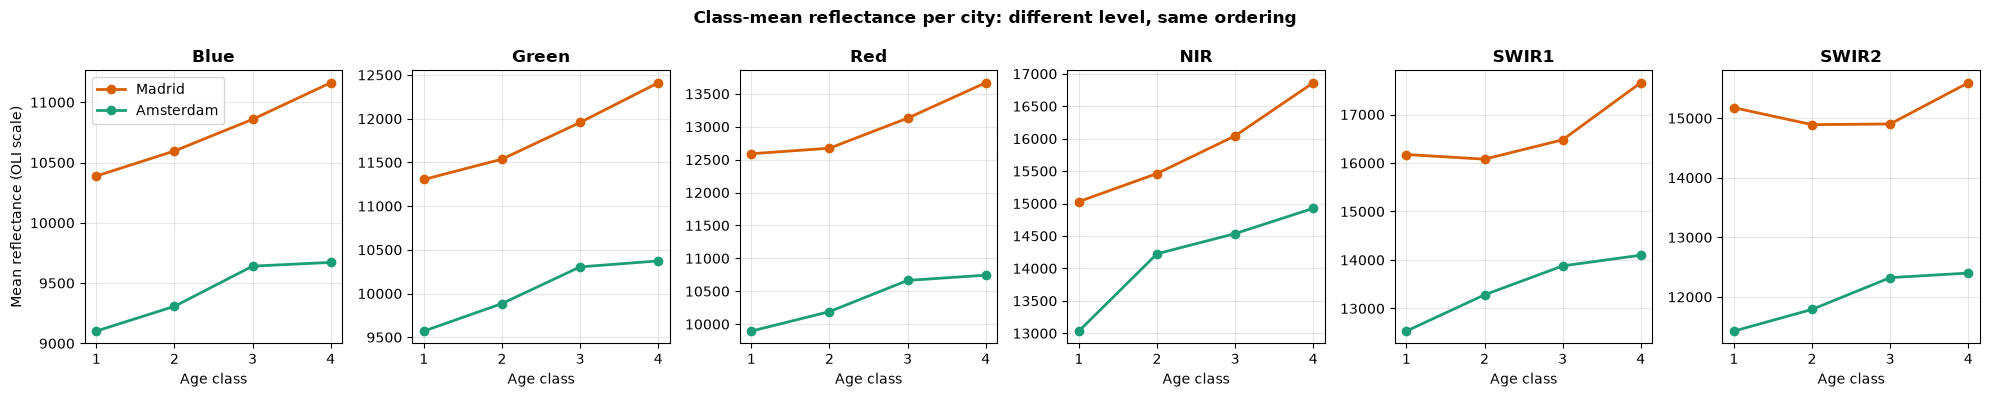

In [6]:
fig, axes = plt.subplots(1, len(BANDS), figsize=(20, 4))
for ax, (b, band) in zip(axes, enumerate(BANDS)):
    for city, d in DATA.items():
        pix_mean = np.nanmean(d['cube'][:, :, b], axis=1)
        ax.plot(range(1, 5), [np.nanmean(pix_mean[Y[city] == k]) for k in range(1, 5)], 'o-',
                color=CITY_COLORS[city], label=city, lw=2)
    ax.set_title(band, fontweight='bold'); ax.set_xticks(range(1, 5)); ax.set_xlabel('Age class'); ax.grid(alpha=.3)
axes[0].set_ylabel('Mean reflectance (OLI scale)'); axes[0].legend()
fig.suptitle('Class-mean reflectance per city: different level, same ordering', fontweight='bold')
plt.tight_layout(); plt.show()

**Interpretation**

* In **every band**, all Amsterdam classes are darker than all Madrid classes.
* Within each city the ordering is the same: **class 1 < 2 < 3 < 4** (newer buildings are brighter).

**Why this matters:** a Madrid model learns absolute thresholds, so Amsterdam pixels fall outside the corresponding Madrid ranges and the baseline collapses toward one class (Notebook 4 zero-shot macro-F1 **0.343**). The transferable part is relative ordering within a city, not raw brightness. The full pipeline raises Amsterdam zero-shot macro-F1 to **0.564**, but the remaining gap is why we adapt locally rather than claim the Madrid model alone solves transfer.

## 7.7 Spectral distributions per class

Means hide overlap. Below are the full distributions of two key signals: NIR brightness and the built-up index NDBI.

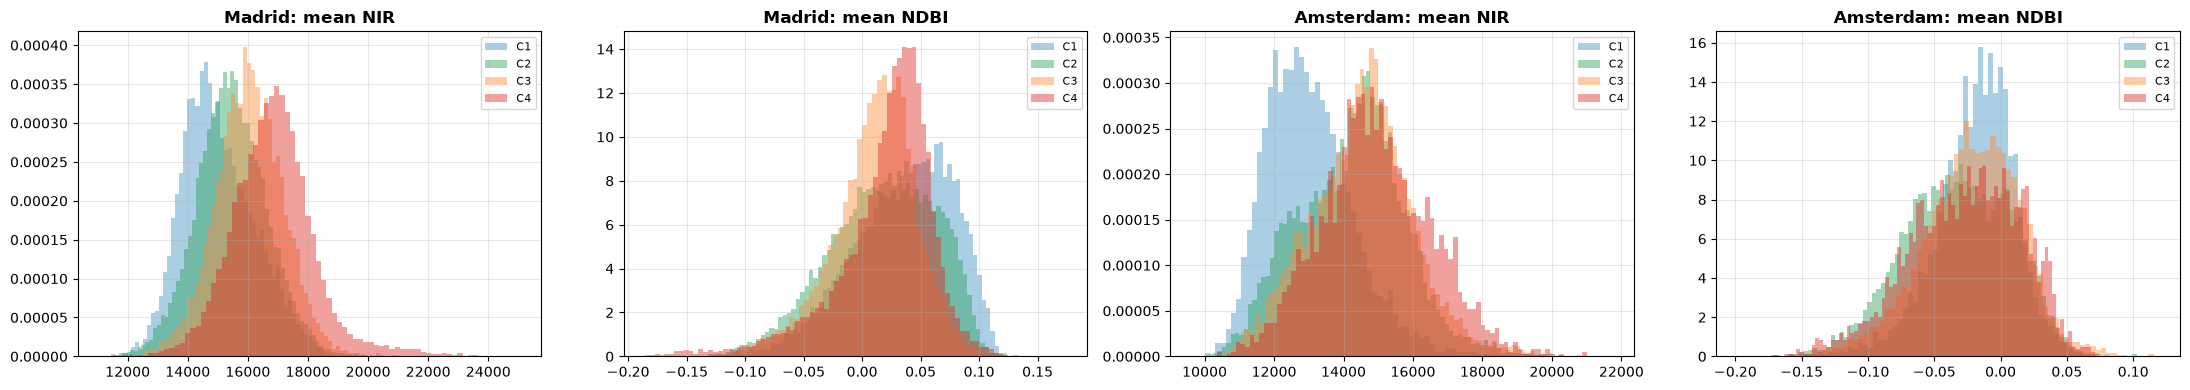

In [7]:
def pixel_index(cube, a, b):
    # Per-pixel mean normalised difference (a - b) / (a + b) over all years.
    with np.errstate(all='ignore'):
        return np.nanmean((cube[:, :, a] - cube[:, :, b]) / (cube[:, :, a] + cube[:, :, b]), axis=1)

fig, axes = plt.subplots(1, 4, figsize=(22, 4))
for i, city in enumerate(CITIES):
    nir = np.nanmean(DATA[city]['cube'][:, :, 3], axis=1)
    ndbi = pixel_index(DATA[city]['cube'], 4, 3)
    for k in range(1, 5):
        axes[2 * i].hist(nir[Y[city] == k], bins=80, alpha=.45, density=True, color=CLASS_COLORS[k], label=f'C{k}')
        axes[2 * i + 1].hist(ndbi[Y[city] == k], bins=80, alpha=.45, density=True, color=CLASS_COLORS[k], label=f'C{k}')
    axes[2 * i].set_title(f'{city}: mean NIR', fontweight='bold'); axes[2 * i + 1].set_title(f'{city}: mean NDBI', fontweight='bold')
for ax in axes: ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Observation:** the class distributions overlap heavily within each city. No single band separates the four classes, so we need *temporal* signals (when did the pixel change?) and *spatial* signals (what are the neighbours?).

## 7.8 City-wide year-to-year shifts

If the whole city brightens or darkens in a given year, that is atmosphere, sensor or season, not buildings.

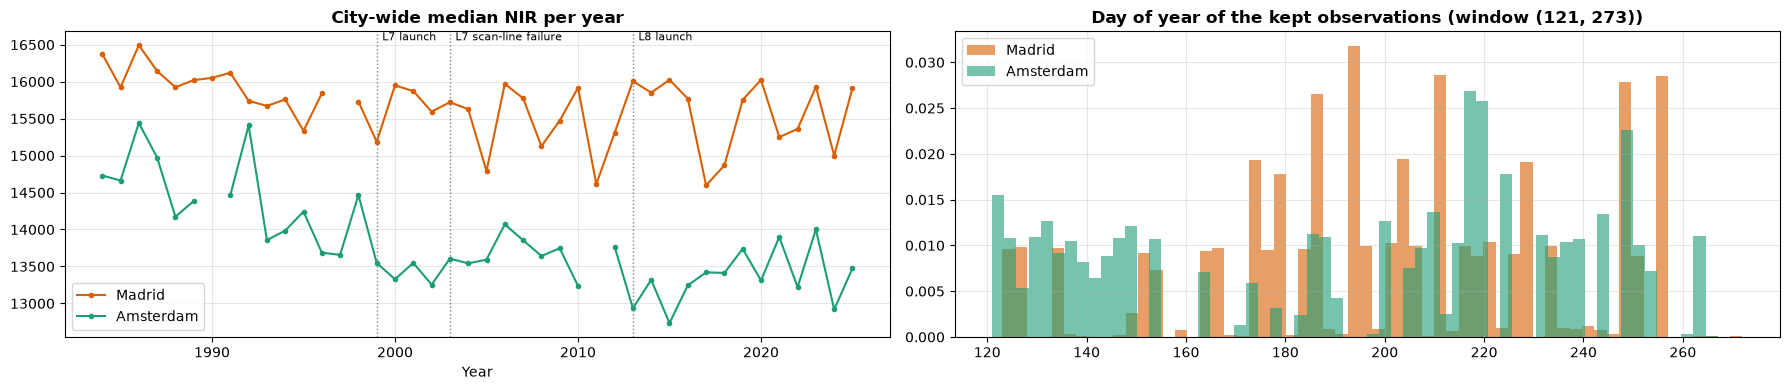

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(18, 4))
for city, d in DATA.items():
    axes[0].plot(YEARS, np.nanmedian(d['cube'][:, :, 3], axis=0), 'o-', ms=3, color=CITY_COLORS[city], label=city)
    axes[1].hist(d['doy'][np.isfinite(d['doy'])], bins=60, alpha=.6, density=True, color=CITY_COLORS[city], label=city)
for yr, lbl in [(1999, 'L7 launch'), (2003, 'L7 scan-line failure'), (2013, 'L8 launch')]:
    axes[0].axvline(yr, color='grey', ls=':', lw=1); axes[0].text(yr + .3, axes[0].get_ylim()[1], lbl, fontsize=8, va='top')
axes[0].set_title('City-wide median NIR per year', fontweight='bold'); axes[0].set_xlabel('Year')
axes[1].set_title(f'Day of year of the kept observations (window {DOY_WINDOW})', fontweight='bold')
for ax in axes: ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Observation:** the city median jumps by up to ~10% from one year to the next. These shifts are **shared by every pixel in the city**, so they say nothing about building age and should be removed (section 7.10).

## 7.9 Building age is spatially clustered

Whole neighbourhoods are built in the same era. We quantify how far that effect reaches: for every distance *d* (in pixels), how often does a pixel share its class with the building pixel *d* cells away?

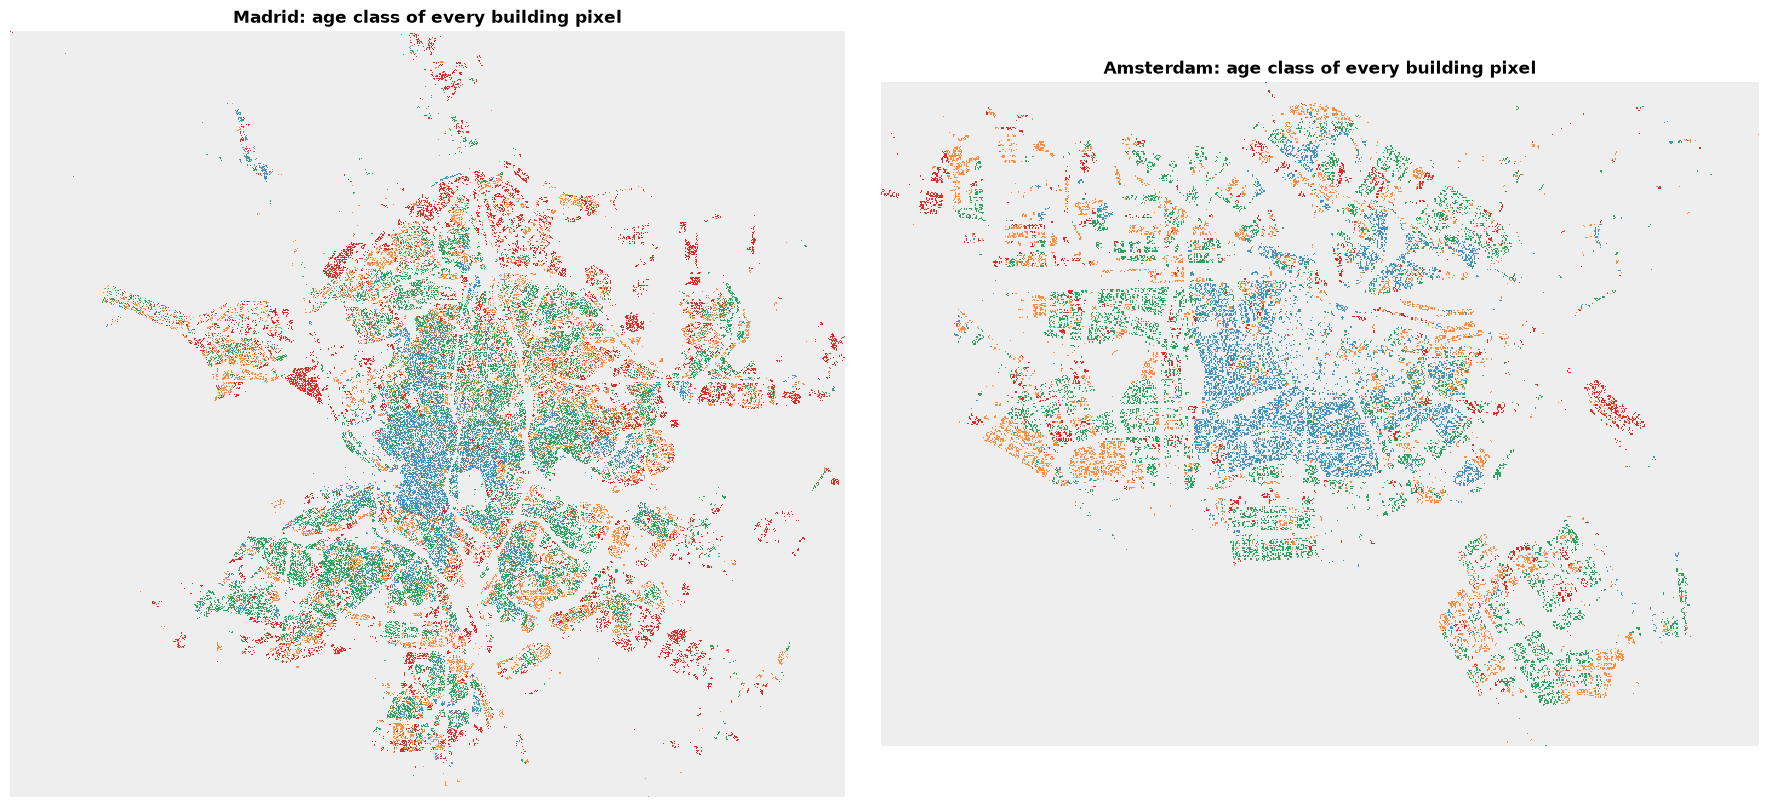

Madrid    : same class at 30 m 78.5%, 150 m 53.6%, 300 m 45.9%  (chance 26.7%)
Amsterdam : same class at 30 m 89.2%, 150 m 67.9%, 300 m 57.5%  (chance 27.9%)


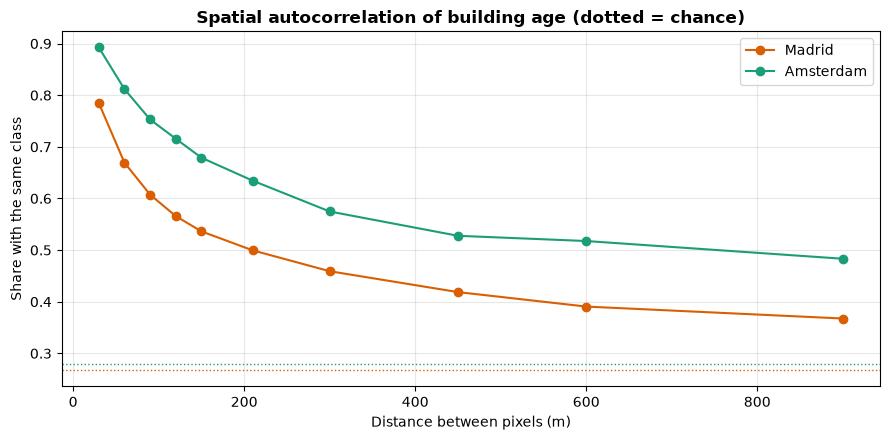

In [9]:
def to_grid(d, values, fill=np.nan):
    gx, gy = d['px'] - d['px'].min(), d['py'] - d['py'].min()
    img = np.full((gy.max() + 1, gx.max() + 1), fill, dtype=np.float32)
    img[gy, gx] = values
    return img[::-1]          # flip so north is up


cmap = ListedColormap([CLASS_COLORS[k] for k in range(1, 5)]); cmap.set_bad('#eeeeee')
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, (city, d) in zip(axes, DATA.items()):
    ax.imshow(to_grid(d, Y[city].astype(float)), cmap=cmap, vmin=.5, vmax=4.5, interpolation='nearest')
    ax.set_title(f'{city}: age class of every building pixel', fontweight='bold'); ax.axis('off')
plt.tight_layout(); plt.show()


def agreement_at_lag(g, lag):
    # Share of building-pixel pairs `lag` cells apart (horizontally or vertically) with the same class.
    same = tot = 0
    for a, b in [(g[:, :-lag], g[:, lag:]), (g[:-lag, :], g[lag:, :])]:
        ok = np.isfinite(a) & np.isfinite(b)
        same += (a[ok] == b[ok]).sum(); tot += ok.sum()
    return same / tot


LAGS = [1, 2, 3, 4, 5, 7, 10, 15, 20, 30]
fig, ax = plt.subplots(figsize=(9, 4.5))
for city, d in DATA.items():
    g = to_grid(d, Y[city].astype(float))
    chance = ((np.bincount(Y[city])[1:] / len(Y[city])) ** 2).sum()
    agr = [agreement_at_lag(g, l) for l in LAGS]
    ax.plot(np.array(LAGS) * 30, agr, 'o-', color=CITY_COLORS[city], label=city)
    ax.axhline(chance, color=CITY_COLORS[city], ls=':', lw=1)
    print(f'{city:10s}: same class at 30 m {agr[0]:.1%}, 150 m {agr[4]:.1%}, 300 m {agr[6]:.1%}  (chance {chance:.1%})')
ax.set_xlabel('Distance between pixels (m)'); ax.set_ylabel('Share with the same class')
ax.set_title('Spatial autocorrelation of building age (dotted = chance)', fontweight='bold'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

**Interpretation and design consequence**

* The saved spatial diagnostics show same-class agreement of **78.5% in Madrid** and **89.2% in Amsterdam** at 30 m, still **45.9%** and **57.5%** at 300 m, versus chance levels of 26.7% and 27.9%.
* This supports neighbourhood features, probability smoothing, and label propagation: nearby pixels contain real era information, not just random noise. Smoothing was tuned on Madrid out-of-fold predictions, not Amsterdam labels.
* The group-drop experiment backs this up: removing all spatial information costs about **0.063** zero-shot F1, **0.040** at n=25, and **0.049** at n=200. Spatial context is useful, but complements rather than replaces spectral and temporal evidence.

---
# Part B-Transfer-oriented feature engineering

## 7.10 Time-series preparation: gap filling, indices, city-year anomaly

1. **Gap filling:** linear interpolation between observed years; nearest value at the edges.
2. **Spectral indices:** NDVI, NDBI, UI, MNDWI and BSI for every year.
3. **City-year anomaly:** for each year and channel, subtract the city-wide median and divide by the city-wide IQR:

$$a_{i,t,c} = \frac{x_{i,t,c} - \mathrm{median}_j\,x_{j,t,c}}{\mathrm{IQR}_j\,x_{j,t,c}}$$

This reads as *"how much brighter or darker than a typical building in this city, this year"*. It removes city offsets (climate, materials; section 7.6) and year noise (atmosphere, sensor changes; section 7.8) in one step. It uses only **unlabelled** imagery, which is always available for a new city.

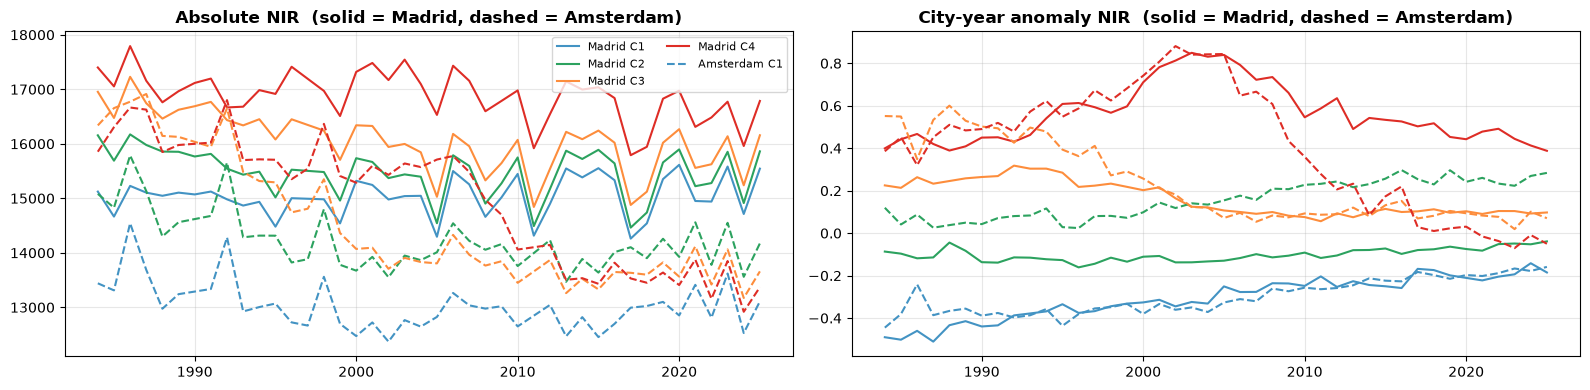

In [10]:
def fill_gaps(cube):
    # Vectorised linear interpolation along the year axis; edges take the nearest valid value.
    c = cube.copy()
    n_pix, n_yr, _ = c.shape
    t = np.arange(n_yr)
    valid = np.isfinite(c[:, :, 0])
    prev = np.maximum.accumulate(np.where(valid, t, -1), axis=1)                    # last valid <= t
    nxt = np.minimum.accumulate(np.where(valid, t, n_yr)[:, ::-1], axis=1)[:, ::-1]  # next valid >= t
    prev_c = np.where(prev < 0, nxt, prev)
    nxt_c = np.where(nxt >= n_yr, prev_c, nxt)
    rows = np.arange(n_pix)[:, None]
    lo, hi = c[rows, prev_c], c[rows, nxt_c]
    w = np.where(nxt_c > prev_c, (t - prev_c) / np.maximum(nxt_c - prev_c, 1), 0.0)[:, :, None]
    return np.where(valid[:, :, None], c, lo + w * (hi - lo)).astype(np.float32)


def add_indices(cube):
    # Append the 5 normalised-difference spectral indices as extra channels.
    B, G, R, N, S1, S2 = [cube[:, :, i] for i in range(6)]
    nd = lambda a, b: (a - b) / (a + b + 1e-6)
    idx = np.stack([nd(N, R), nd(S1, N), nd(S2, N), nd(G, S1), nd(S1 + R, N + B)], axis=2)
    return np.concatenate([cube, idx.astype(np.float32)], axis=2)


def city_year_anomaly(series):
    # Robust z-score of every value against all pixels of the same city in the same year.
    med = np.nanmedian(series, axis=0, keepdims=True)
    q75, q25 = np.nanpercentile(series, [75, 25], axis=0, keepdims=True)
    return ((series - med) / (q75 - q25 + 1e-6)).astype(np.float32)


SERIES = {city: add_indices(fill_gaps(DATA[city]['cube'])) for city in CITIES}
ANOM   = {city: city_year_anomaly(SERIES[city]) for city in CITIES}

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, src, title in [(axes[0], SERIES, 'Absolute NIR'), (axes[1], ANOM, 'City-year anomaly NIR')]:
    for city, ls in [('Madrid', '-'), ('Amsterdam', '--')]:
        for k in range(1, 5):
            ax.plot(YEARS, src[city][Y[city] == k, :, 3].mean(0), ls, color=CLASS_COLORS[k],
                    label=f'{city} C{k}' if city == 'Madrid' or k == 1 else None)
    ax.set_title(f'{title}  (solid = Madrid, dashed = Amsterdam)', fontweight='bold'); ax.grid(alpha=.3)
axes[0].legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

**Left:** in absolute NIR, the year-to-year noise (shared by all classes) is larger than the gaps between classes, and the Amsterdam curves sit below the Madrid ones.

**Right:** after the anomaly transform the shared noise is gone and the two cities line up:

* The class ordering (1 lowest → 4 highest) is the same in both cities.
* **Class 4 has a construction bump**: it rises while those sites are cleared and built, then falls back. Class 3 shows the same bump earlier. The *timing* of the bump tracks the construction period, and the change-point features below are designed to catch it.

## 7.11 Per-pixel features (166 per pixel)

| Group | Per channel | What it captures |
|---|---|---|
| Level & spread | mean, std | Material brightness / variability |
| Trend | linear slope, late (2004+) minus early (≤2003) mean | Long-term ageing / change |
| Period means | 5 periods: 84–91, 92–99, 00–07, 08–15, 16–25 | *When* the signal changed |
| Year-on-year | std and max \|change\| | Construction disturbance |
| **Change-point** | best single break year, its strength, per-channel jump | **Construction event detection** (classes 3–4) |
| Largest jump | year and size of the largest year-to-year spectral change | Second construction-event estimate |
| Stability | mean std before vs after 2004 | Pre-1984 buildings are stable in both periods |
| **Neighbourhood context** | mean of the level and change-point features over 150 m and 330 m windows, plus building density | Neighbourhoods are built in the same era (section 7.9) |

**Change-point detection.** After a 3-year running mean, we try every split year *k* and score a two-level step fit:

$$\text{score}(k) = \frac{k(T-k)}{T}\,\big\lVert \bar a_{\text{after }k} - \bar a_{\text{before }k} \big\rVert^2$$

The best *k* estimates **when the surface changed**, which for classes 3 and 4 is roughly the construction year. It uses no labels.

**Per-city robust scaling.** Finally, each feature is scaled by its own city's median and IQR (again, unlabelled pixels only).

**Interpretation of the transfer diagnostics.** The city-year anomaly removes shared city/year shifts and per-city robust scaling reduces the median per-feature KS distance from **0.35 to 0.05**. That is substantial marginal alignment, but the adversarial city classifier still reaches **AUC about 1**: the cities remain distinguishable when features are considered jointly. These features make transfer more plausible, not domain-invariant. Stage 2 must use Amsterdam labels and its unlabelled imagery to recalibrate the residual city gap.

In [11]:
PERIODS = [(1984, 1991), (1992, 1999), (2000, 2007), (2008, 2015), (2016, 2025)]


def breakpoint_features(s, min_seg=3):
    # Best single change-point per pixel (two-segment mean fit scanned over all split years).
    n_pix, T, C = s.shape
    cs = np.cumsum(s, axis=1); total = cs[:, -1, :]
    best_score = np.full(n_pix, -np.inf, dtype=np.float32)
    best_k = np.zeros(n_pix, dtype=np.int32)
    best_jump = np.zeros((n_pix, C), dtype=np.float32)
    for k in range(min_seg, T - min_seg + 1):
        jump = (total - cs[:, k - 1, :]) / (T - k) - cs[:, k - 1, :] / k   # mean after - mean before
        score = (k * (T - k) / T) * (jump ** 2).sum(1)
        better = score > best_score
        best_score[better], best_k[better], best_jump[better] = score[better], k, jump[better]
    return YEARS[best_k].astype(np.float32), np.sqrt(best_score), best_jump


def pixel_features(series):
    # Collapse (pixels, years, channels) into a per-pixel feature table (Notebook 5's 140 features).
    f = {}
    t = np.arange(len(YEARS), dtype=np.float32); t -= t.mean()
    mean, std = series.mean(1), series.std(1)
    slope = (series * t[None, :, None]).sum(1) / (t ** 2).sum()
    early, late = series[:, YEARS <= 2003].mean(1), series[:, YEARS >= 2004].mean(1)
    d = np.diff(series, axis=1)
    for j, ch in enumerate(CHANNELS):
        f[f'{ch}_mean'], f[f'{ch}_std'] = mean[:, j], std[:, j]
        f[f'{ch}_slope'] = slope[:, j]
        f[f'{ch}_late_minus_early'] = late[:, j] - early[:, j]
        f[f'{ch}_dstd'] = d[:, :, j].std(1)
        f[f'{ch}_dmaxabs'] = np.abs(d[:, :, j]).max(1)
        for a, b in PERIODS:
            f[f'{ch}_p{a}'] = series[:, (YEARS >= a) & (YEARS <= b), j].mean(1)

    # 3-year running mean before change detection (suppresses single-scene noise)
    smooth = series.copy()
    smooth[:, 1:-1] = (series[:, :-2] + series[:, 1:-1] + series[:, 2:]) / 3
    f['break_year'], f['break_strength'], jump = breakpoint_features(smooth)
    for j, ch in enumerate(CHANNELS):
        f[f'{ch}_break_jump'] = jump[:, j]
    dnorm = np.sqrt((np.diff(smooth, axis=1) ** 2).sum(2))
    f['maxjump_year'] = YEARS[1:][dnorm.argmax(1)].astype(np.float32)
    f['maxjump_size'] = dnorm.max(1)
    f['std_early'] = series[:, YEARS <= 2003].std(1).mean(1)
    f['std_late'] = series[:, YEARS >= 2004].std(1).mean(1)
    return pd.DataFrame(f)


def spatial_context(feat, px, py, cols, radii=(2, 5)):
    # Mean of `cols` over building pixels within a (2r+1)x(2r+1) window, plus building density.
    gx, gy = px - px.min(), py - py.min()
    H, W = gy.max() + 1, gx.max() + 1
    mask = np.zeros((H, W), np.float32); mask[gy, gx] = 1
    out = {}
    for r in radii:
        size = 2 * r + 1
        cnt = uniform_filter(mask, size, mode='constant')
        out[f'ctx{r}_density'] = cnt[gy, gx]
        for c in cols:
            g = np.zeros((H, W), np.float32); g[gy, gx] = feat[c].values
            out[f'ctx{r}_{c}'] = (uniform_filter(g, size, mode='constant') / np.maximum(cnt, 1e-6))[gy, gx]
    return pd.DataFrame(out)


def build_features(d, tag):
    # Final per-pixel table: city-relative time-series features + neighbourhood context (cached).
    path = CACHE_DIR / f'nb7_features_{tag}.parquet'
    if path.exists():
        return pd.read_parquet(path)
    anom = city_year_anomaly(add_indices(fill_gaps(d['cube'])))
    rel = pixel_features(anom)
    ctx_cols = [c for c in rel.columns if c.endswith('_mean') or c in ('break_year', 'break_strength')]
    feat = pd.concat([rel, spatial_context(rel, d['px'], d['py'], ctx_cols)], axis=1)
    feat.to_parquet(path)
    return feat


def city_scale(df):
    # Robust z-score of every feature against its own city (unsupervised, no labels used).
    return (df - df.median()) / (df.quantile(.75) - df.quantile(.25) + 1e-9)


def spatial_blocks(px, py, block_m=1000):
    # Id of the square block (default 1 km) that each pixel falls in.
    cells = int(round(block_m / 30))
    return ((px - px.min()) // cells).astype(np.int64) * 100_000 + (py - py.min()) // cells


SEASON_TAG = 'all' if DOY_WINDOW is None else f'{DOY_WINDOW[0]}-{DOY_WINDOW[1]}'
t0 = time.time()
FEAT = {}
for city in CITIES:
    path = CACHE_DIR / f'nb7_features_{city}_{SEASON_TAG}.parquet'
    if path.exists():
        FEAT[city] = pd.read_parquet(path)
    else:
        rel = pixel_features(ANOM[city])
        ctx_cols = [c for c in rel.columns if c.endswith('_mean') or c in ('break_year', 'break_strength')]
        FEAT[city] = pd.concat([rel, spatial_context(rel, DATA[city]['px'], DATA[city]['py'], ctx_cols)], axis=1)
        FEAT[city].to_parquet(path)
print(f'Features built in {time.time() - t0:.0f}s')
for city, f in FEAT.items():
    print(f'{city:10s} {f.shape[0]:,} pixels x {f.shape[1]} features   NaN: {int(f.isna().sum().sum())}')

# For the season-filter ablation (section 7.18): the same features without the day-of-year window
FEAT_ALL = None
if RUN_SEASON_ABLATION and DOY_WINDOW is not None:
    t0 = time.time()
    FEAT_ALL = {}
    for city in CITIES:
        FEAT_ALL[city] = build_features(load_cube(city, doy_window=None), f'{city}_all')
        gc.collect()
    print(f'No-season-filter features built in {time.time() - t0:.0f}s')

Features built in 0s
Madrid     76,263 pixels x 166 features   NaN: 0
Amsterdam  25,992 pixels x 166 features   NaN: 0
No-season-filter features built in 1s


## 7.12 Does the change-point year track the construction year?

If the break detector works, the detected `break_year` should follow the true construction year for buildings built during the satellite record (1984+).

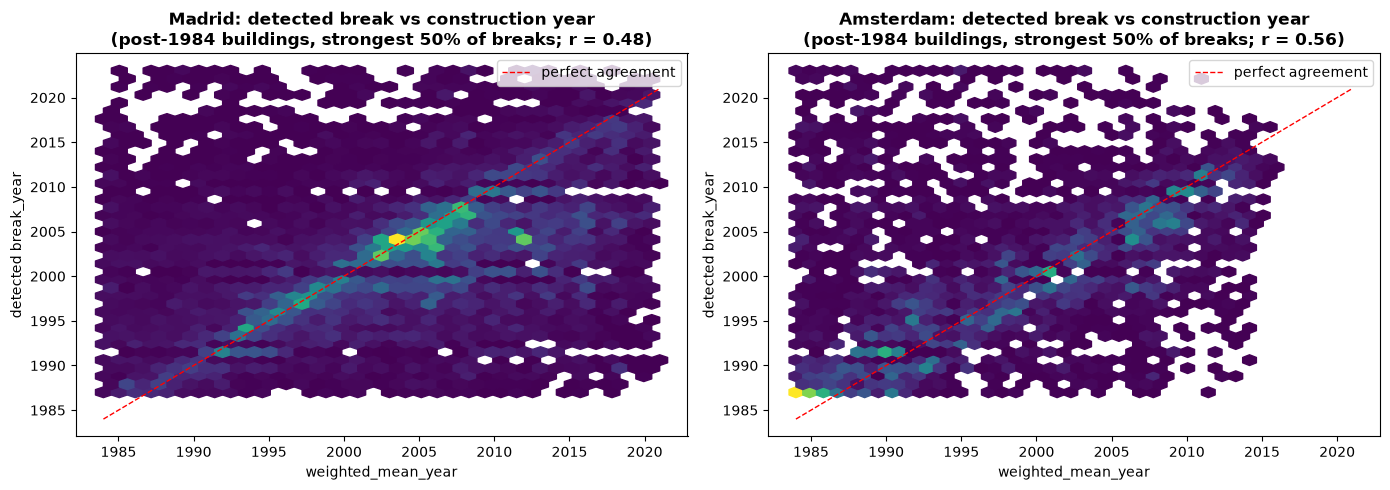

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, city in zip(axes, CITIES):
    w, by, bs = DATA[city]['wmy'], FEAT[city]['break_year'].values, FEAT[city]['break_strength'].values
    strong = (w >= 1984) & (bs > np.percentile(bs, 50))
    ax.hexbin(w[strong], by[strong], gridsize=35, cmap='viridis', mincnt=1)
    ax.plot([1984, 2021], [1984, 2021], 'r--', lw=1, label='perfect agreement')
    r = np.corrcoef(w[strong], by[strong])[0, 1]
    ax.set_title(f'{city}: detected break vs construction year\n(post-1984 buildings, strongest 50% of breaks; r = {r:.2f})',
                 fontweight='bold')
    ax.set_xlabel('weighted_mean_year'); ax.set_ylabel('detected break_year'); ax.legend()
plt.tight_layout(); plt.show()

**Observation:** for post-1984 buildings the detected break year follows the true construction year in **both** cities (about r = 0.5), without using labels. This gives a useful, city-independent estimate of *when* a surface changed, particularly for classes 3 and 4. It is not a perfect construction-year predictor, and its value is complementary to the full temporal trajectory rather than a standalone solution.

## 7.13 Domain-shift diagnostics: did the features close the gap between cities?

Three quantitative checks of transferability, comparing three feature sets:

* **absolute**: the same 140 time-series features on raw reflectance (Notebook 3 style)
* **city-year anomaly**: our anomaly features, before per-city scaling
* **final**: anomaly + context + per-city scaling (the model input)

1. **Per-feature shift (KS statistic).** For every feature, the Kolmogorov–Smirnov distance between its Madrid and Amsterdam distributions (0 = identical, 1 = no overlap).
2. **Adversarial validation.** A classifier tries to tell **Madrid pixels from Amsterdam pixels** using *all* features jointly (AUC 1 = perfectly separable).
3. **Feature–age consistency.** For each feature, the Spearman correlation with construction year in Madrid vs Amsterdam. Features on the diagonal mean the same thing in both cities.

,median KS (per feature),features with KS < 0.1,adversarial AUC (joint)
absolute (Notebook 3 style),0.353,3%,1.000
city-year anomaly,0.073,64%,1.000
"final (+context, city-scaled)",0.050,93%,1.000


,"KS, final features"
maxjump_year,0.278
ctx2_density,0.153
SWIR2_std,0.136
SWIR2_dmaxabs,0.117
ctx2_break_strength,0.117
SWIR2_break_jump,0.116
BSI_break_jump,0.116
break_strength,0.113


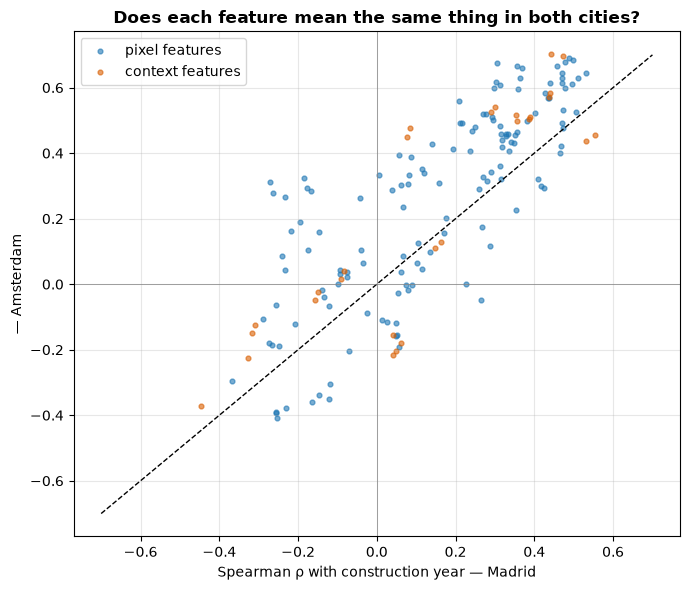

Features with |rho| > 0.1 in Madrid that keep the same sign in Amsterdam: 90% of 128
Correlation between the two cities' feature-age correlations: 0.81


In [13]:
from scipy.stats import ks_2samp


def adversarial_auc(A, B, seed=SEED):
    # Out-of-fold AUC of a classifier separating city A from city B (1.0 = fully separable).
    Z = np.vstack([A, B]); lab = np.r_[np.zeros(len(A)), np.ones(len(B))]
    oof = np.zeros(len(lab))
    for tr, va in StratifiedKFold(3, shuffle=True, random_state=seed).split(Z, lab):
        m = lgb.LGBMClassifier(n_estimators=150, learning_rate=0.1, num_leaves=31, colsample_bytree=0.5,
                               n_jobs=N_JOBS, verbose=-1, random_state=seed)
        oof[va] = m.fit(Z[tr], lab[tr]).predict_proba(Z[va])[:, 1]
    return roc_auc_score(lab, oof)


rng_adv = np.random.default_rng(SEED)
sub = {c: rng_adv.choice(len(Y[c]), min(len(Y[c]), 20_000), replace=False) for c in CITIES}
rel_cols = [c for c in FEAT['Madrid'].columns if not c.startswith('ctx')]
SETS = {
    'absolute (Notebook 3 style)':   {c: pixel_features(SERIES[c][sub[c]]).values for c in CITIES},
    'city-year anomaly':             {c: FEAT[c][rel_cols].values[sub[c]] for c in CITIES},
    'final (+context, city-scaled)': {c: city_scale(FEAT[c]).values[sub[c]] for c in CITIES},
}
shift = {}
for name, S in SETS.items():
    ks = np.array([ks_2samp(S['Madrid'][:, j], S['Amsterdam'][:, j]).statistic for j in range(S['Madrid'].shape[1])])
    shift[name] = {'median KS (per feature)': np.median(ks), 'features with KS < 0.1': (ks < .1).mean(),
                   'adversarial AUC (joint)': adversarial_auc(S['Madrid'], S['Amsterdam'])}
display(pd.DataFrame(shift).T.style.format({'median KS (per feature)': '{:.3f}', 'features with KS < 0.1': '{:.0%}',
                                            'adversarial AUC (joint)': '{:.3f}'}))
F = SETS['final (+context, city-scaled)']
ks_final = pd.Series([ks_2samp(F['Madrid'][:, j], F['Amsterdam'][:, j]).statistic for j in range(F['Madrid'].shape[1])],
                     index=FEAT['Madrid'].columns).sort_values(ascending=False)
display(ks_final.head(8).to_frame('KS, final features').style.format('{:.3f}')
        .set_caption('Most city-specific features after all normalisation'))
del SETS, F; gc.collect()

# Feature-age consistency between the two cities
rho = pd.DataFrame({c: [spearmanr(FEAT[c][f].values, DATA[c]['wmy'])[0] for f in FEAT[c].columns] for c in CITIES},
                   index=FEAT['Madrid'].columns)
fig, ax = plt.subplots(figsize=(7, 6))
is_ctx = rho.index.str.startswith('ctx')
ax.scatter(rho.loc[~is_ctx, 'Madrid'], rho.loc[~is_ctx, 'Amsterdam'], s=12, alpha=.6, label='pixel features')
ax.scatter(rho.loc[is_ctx, 'Madrid'], rho.loc[is_ctx, 'Amsterdam'], s=12, alpha=.6, color='#d95f02', label='context features')
ax.plot([-.7, .7], [-.7, .7], 'k--', lw=1); ax.axhline(0, color='grey', lw=.5); ax.axvline(0, color='grey', lw=.5)
ax.set_xlabel('Spearman ρ with construction year — Madrid'); ax.set_ylabel('— Amsterdam')
ax.set_title('Does each feature mean the same thing in both cities?', fontweight='bold'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
strong = rho['Madrid'].abs() > .1
same_sign = (np.sign(rho['Madrid']) == np.sign(rho['Amsterdam']))[strong]
print(f'Features with |rho| > 0.1 in Madrid that keep the same sign in Amsterdam: {same_sign.mean():.0%} of {strong.sum()}')
print(f"Correlation between the two cities' feature-age correlations: {np.corrcoef(rho['Madrid'], rho['Amsterdam'])[0, 1]:.2f}")

**How to read this** (numbers from our development run; the table above is recomputed on every run)

* **Per feature, the gap almost closes.** The median KS distance between the cities falls from about 0.35 (absolute reflectance) to about 0.07 (anomaly) and 0.05 (final). The share of features whose two city distributions nearly coincide (KS < 0.1) rises from about 3% to over 90%. This is why zero-shot F1 jumps from 0.343 to above 0.5.
* **Jointly, the cities remain perfectly distinguishable** (adversarial AUC ≈ 1.0). The *combination* of features still differs, e.g. building density and how sharply construction events show. A Madrid model therefore cannot be used as-is, and this is exactly what Stage 2 (few-shot adaptation plus self-training on Amsterdam's own imagery) is for.
* **The most city-specific feature is `maxjump_year`**, the year of the largest spectral jump. The jump is often the **sensor switch** rather than construction: Amsterdam moves to Landsat 8 in 2014, Madrid in 2017 (section 7.3). The change-point features based on a two-segment fit are far less affected.
* Most features keep the **same sign** of correlation with construction year in both cities: the *direction* of the age signal transfers, the magnitudes need local recalibration.

---
# Part C-Stage 1: what does Madrid teach us?

## 7.14 Model inputs and spatial blocks

| Step | Madrid labels | Amsterdam labels | Unlabelled Amsterdam pixels |
|---|:-:|:-:|:-:|
| Feature engineering, per-city scaling | — | ✗ | ✓ (city-year medians/IQRs) |
| Stage 1 training | ✓ | ✗ | ✗ |
| Stage 2 adaptation | — | only the *n*-per-class support set | ✓ (smoothing, self-training) |
| Scoring | — | only pixels **not** in the support set | — |

Section 7.9 showed that neighbouring pixels are strongly correlated, so random CV folds put near-copies of test pixels into training. We therefore cross-validate on **1 km × 1 km spatial blocks**: whole blocks are held out together.

`CityGrid` rasterises a city's building pixels so that neighbourhood operations (smoothing, label propagation, prediction context) are fast box filters.

In [14]:
class CityGrid:
    # Raster view of a city's building pixels, used for all neighbourhood operations.
    def __init__(self, px, py):
        self.gx, self.gy = px - px.min(), py - py.min()
        self.shape = (self.gy.max() + 1, self.gx.max() + 1)
        self.n = len(px)

    def box_sum(self, v, size):
        # Sum of v over the building pixels in a size x size window around every pixel.
        g = np.zeros(self.shape, np.float32); g[self.gy, self.gx] = v
        return uniform_filter(g, size, mode='constant')[self.gy, self.gx] * size * size

    def neighbour_mean(self, P, size):
        # Mean of each column of P over the *other* building pixels in the window (self excluded).
        cnt = self.box_sum(np.ones(self.n, np.float32), size) - 1
        return np.stack([np.maximum(self.box_sum(P[:, k], size) - P[:, k], 0) / np.maximum(cnt, 1e-6)
                         for k in range(P.shape[1])], 1)


def softmax(S):
    e = np.exp(S - S.max(1, keepdims=True))
    return e / e.sum(1, keepdims=True)


SMOOTH_SIZE, SMOOTH_BETA = 5, 1.0      # defaults; re-tuned on Madrid out-of-fold predictions (section 7.16)


def smooth_scores(S, grid, size=None, beta=None):
    # Spatial smoothing: a pixel's own class log-probabilities plus beta x the log of its
    # neighbours' mean probabilities. Neighbourhoods are built in one era (section 7.9).
    size, beta = size or SMOOTH_SIZE, SMOOTH_BETA if beta is None else beta
    P = softmax(S)
    return np.log(P + 1e-6) + beta * np.log(grid.neighbour_mean(P, size) + 1e-6)


def label_votes(sup, y_sup, grid, size=11, prior=0.5):
    # Spatial label propagation: log share of each class among the *labelled* neighbours
    # (self excluded), with a flat prior so pixels without labelled neighbours get 0 evidence.
    V = np.zeros((grid.n, 4), np.float32)
    for c in range(4):
        oh = np.zeros(grid.n, np.float32); oh[sup[y_sup == c + 1]] = 1
        V[:, c] = grid.box_sum(oh, size) - oh
    return np.log((V + prior) / (V.sum(1, keepdims=True) + 4 * prior))


X = {city: city_scale(FEAT[city]).values.astype(np.float32) for city in CITIES}
FEATURE_NAMES = list(FEAT['Madrid'].columns)
Xm, ym = X['Madrid'], Y['Madrid']
Xa, ya = X['Amsterdam'], Y['Amsterdam']
GRID = {city: CityGrid(DATA[city]['px'], DATA[city]['py']) for city in CITIES}
groups_m = spatial_blocks(DATA['Madrid']['px'], DATA['Madrid']['py'])
print(f'Madrid {Xm.shape} | Amsterdam {Xa.shape} | {len(np.unique(groups_m)):,} spatial blocks of 1 km in Madrid')

Madrid (76263, 166) | Amsterdam (25992, 166) | 419 spatial blocks of 1 km in Madrid


## 7.15 The Stage 1 model zoo

All models use **balanced class weights** (class 2 dominates Madrid). We compare four families:

| Key | Model | Family |
|---|---|---|
| `lgbm` | LightGBM (Notebook 5) | Boosting, leaf-wise trees |
| `rf` | Random Forest | Bagging, deep trees |
| `cat` | CatBoost | Boosting, symmetric (oblivious) trees |
| `et` | Extra Trees | Bagging, randomised trees |
| **ensemble** | Mean of the members' log-probabilities | Bagging + boosting |

For each model we run `N_FOLDS`-fold **spatial** CV on Madrid, keeping the out-of-fold probabilities, then fit on all of Madrid and predict Amsterdam. The out-of-fold probabilities give the **ensemble's Madrid CV for free** (no extra training). Results are cached in `data/cache/`, so a re-run skips finished models.

This is the slowest cell: about 5–15 minutes per model on 4 cores.

In [15]:
EPS = 1e-3      # probability floor before logs (bagged trees can output exact zeros)

ZOO = {
    'lgbm': lambda: lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=63, subsample=0.8,
                                       subsample_freq=1, colsample_bytree=0.5, class_weight='balanced',
                                       n_jobs=N_JOBS, verbose=-1, random_state=SEED),
    'rf':   lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=3, max_features='sqrt',
                                           class_weight='balanced', n_jobs=N_JOBS, random_state=SEED),
    'et':   lambda: ExtraTreesClassifier(n_estimators=300, min_samples_leaf=3, max_features='sqrt',
                                         class_weight='balanced', n_jobs=N_JOBS, random_state=SEED),
}
if CatBoostClassifier is not None:
    ZOO['cat'] = lambda: CatBoostClassifier(iterations=600, depth=6, learning_rate=0.08, auto_class_weights='Balanced',
                                            thread_count=N_JOBS, random_seed=SEED, verbose=0, allow_writing_files=False)
STAGE1_MODELS = [m for m in STAGE1_MODELS if m in ZOO]


def log_proba(model, Z):
    return np.log(np.clip(model.predict_proba(Z), EPS, 1)).astype(np.float32)


def save_stage1(name, model):
    # LightGBM / CatBoost have native formats; the sklearn forests are pickled (compressed).
    if name == 'lgbm':
        model.booster_.save_model(str(MODEL_DIR / 'nb7_stage1_lgbm.txt'))
    elif name == 'cat':
        model.save_model(str(MODEL_DIR / 'nb7_stage1_cat.cbm'))
    else:
        import joblib
        joblib.dump(model, MODEL_DIR / f'nb7_stage1_{name}.joblib', compress=3)


folds = list(StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED).split(Xm, ym, groups_m))
OOF, LOGP, CV_F1 = {}, {}, {}
for name in STAGE1_MODELS:
    path = CACHE_DIR / f'nb7_stage1_{name}_{SEASON_TAG}{"_quick" if QUICK else ""}.npz'
    if path.exists():
        z = np.load(path); OOF[name], LOGP[name], CV_F1[name] = z['oof'], z['logp'], z['cv']
        print(f'{name:5s} (cached)', end='  ')
    else:
        t0 = time.time()
        oof = np.zeros((len(ym), 4), np.float32); f1s = []
        for tr, va in folds:
            m = ZOO[name]().fit(Xm[tr], ym[tr])
            oof[va] = log_proba(m, Xm[va])
            f1s.append(f1_score(ym[va], oof[va].argmax(1) + 1, average='macro'))
            del m; gc.collect()
        final = ZOO[name]().fit(Xm, ym)
        LOGP[name], OOF[name], CV_F1[name] = log_proba(final, Xa), oof, np.array(f1s)
        save_stage1(name, final); del final; gc.collect()
        np.savez(path, oof=OOF[name], logp=LOGP[name], cv=CV_F1[name])
        print(f'{name:5s} {time.time() - t0:5.0f}s', end='  ')
    print(f'Madrid spatial CV {CV_F1[name].mean():.4f} ± {CV_F1[name].std():.4f} | '
          f'Amsterdam zero-shot {f1_score(ya, LOGP[name].argmax(1) + 1, average="macro"):.4f}')

lgbm  (cached)  Madrid spatial CV 0.6461 ± 0.0097 | Amsterdam zero-shot 0.5368
rf    (cached)  Madrid spatial CV 0.6319 ± 0.0098 | Amsterdam zero-shot 0.5559
cat   (cached)  Madrid spatial CV 0.6357 ± 0.0102 | Amsterdam zero-shot 0.5678
et    (cached)  Madrid spatial CV 0.6279 ± 0.0131 | Amsterdam zero-shot 0.5386


## 7.16 Stage 1 comparison and the Madrid CV deliverable

The ensemble averages the members' log-probabilities (a geometric mean of probabilities). Its Madrid CV is computed per fold from the members' out-of-fold predictions.

In [16]:
def ensemble(members, source):
    return np.mean([source[m] for m in members], axis=0)


def fold_f1(oof):
    return np.array([f1_score(ym[va], oof[va].argmax(1) + 1, average='macro') for _, va in folds])


ENSEMBLES = {'ensemble (all)': STAGE1_MODELS}
if {'lgbm', 'rf', 'cat'} <= set(STAGE1_MODELS):
    ENSEMBLES['ensemble (lgbm+rf+cat)'] = ['lgbm', 'rf', 'cat']
for e, members in ENSEMBLES.items():
    OOF[e], LOGP[e] = ensemble(members, OOF), ensemble(members, LOGP)
    CV_F1[e] = fold_f1(OOF[e])

stage1_table = pd.DataFrame({
    'Madrid spatial CV (mean)': {m: CV_F1[m].mean() for m in LOGP},
    'Madrid spatial CV (std)':  {m: CV_F1[m].std() for m in LOGP},
    'Amsterdam zero-shot':      {m: f1_score(ya, LOGP[m].argmax(1) + 1, average='macro') for m in LOGP},
})
display(stage1_table.style.format('{:.4f}').highlight_max(subset=['Madrid spatial CV (mean)', 'Amsterdam zero-shot'],
                                                         color='#c7e9c0'))


def plot_cm(ax, y_true, y_pred, title):
    # Row-normalised confusion matrix (each row = recall of that true class).
    cm = confusion_matrix(y_true, y_pred, labels=[1, 2, 3, 4]).astype(float)
    cm /= cm.sum(1, keepdims=True)
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', color='white' if cm[i, j] > .6 else 'black')
    ax.set_xticks(range(4)); ax.set_xticklabels([f'C{k}' for k in range(1, 5)])
    ax.set_yticks(range(4)); ax.set_yticklabels([f'C{k}' for k in range(1, 5)])
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title(title, fontweight='bold', fontsize=10)

,Madrid spatial CV (mean),Madrid spatial CV (std),Amsterdam zero-shot
lgbm,0.6461,0.0097,0.5368
rf,0.6319,0.0098,0.5559
cat,0.6357,0.0102,0.5678
et,0.6279,0.0131,0.5386
ensemble (all),0.6443,0.0093,0.5638
ensemble (lgbm+rf+cat),0.6448,0.0098,0.5631


**Interpretation of Stage 1.** No single model leads on every transfer measure. In the saved spatial-block CV, LightGBM has the strongest individual Madrid CV (**0.6461 +/- 0.0097**); CatBoost has the best individual Amsterdam zero-shot score (**0.5678**), ahead of RF (**0.5559**), Extra Trees (**0.5386**) and LightGBM (**0.5368**). So Madrid CV is not a reliable proxy for Amsterdam transfer. After adaptation, the model-family scores are close, but **per-member adaptation** is the strongest fixed setup in the tournament (average macro-F1 **0.723**, versus **0.720** for the all-member ensemble). The final procedure goes one step further: it selects a configuration per label budget on development draws, then evaluates that rule on fresh draws.

### Tuning the spatial smoothing on Madrid only

The smoothing window and strength are chosen on **Madrid out-of-fold predictions** from spatial-block CV; no Amsterdam labels are used. The saved sweep selects a **7 x 7** window (210 m) and **beta = 0.5**, raising Madrid spatial-CV F1 from **0.6443 to 0.6512**. This supports a conservative spatial prior; it does not justify smoothing so aggressively that local class boundaries disappear.

In [17]:
FINAL_STAGE1 = 'ensemble (all)'      # chosen in development: ties on average F1, best at n = 25 (section 7.19)
SIZES, BETAS = [3, 5, 7, 9, 11], [0.5, 1.0, 1.5, 2.0, 3.0]
smooth_grid = pd.DataFrame({f'{s}x{s} ({s * 30} m)': [f1_score(ym, smooth_scores(OOF[FINAL_STAGE1], GRID['Madrid'], s, b)
                                                               .argmax(1) + 1, average='macro') for b in BETAS]
                            for s in SIZES}, index=[f'beta = {b}' for b in BETAS])
display(smooth_grid.style.format('{:.4f}').highlight_max(axis=None, color='#c7e9c0'))
b_idx, s_idx = np.unravel_index(smooth_grid.values.argmax(), smooth_grid.shape)
SMOOTH_SIZE, SMOOTH_BETA = SIZES[s_idx], BETAS[b_idx]
print(f'Chosen on Madrid: window {SMOOTH_SIZE}x{SMOOTH_SIZE}, beta {SMOOTH_BETA}  ->  Madrid spatial-CV F1 '
      f'{CV_F1[FINAL_STAGE1].mean():.4f} (pooled {f1_score(ym, OOF[FINAL_STAGE1].argmax(1) + 1, average="macro"):.4f}) '
      f'-> {smooth_grid.values.max():.4f} with smoothing')

,3x3 (90 m),5x5 (150 m),7x7 (210 m),9x9 (270 m),11x11 (330 m)
beta = 0.5,0.6473,0.6511,0.6512,0.6509,0.6504
beta = 1.0,0.6461,0.6507,0.6500,0.6487,0.6478
beta = 1.5,0.6453,0.6484,0.6470,0.6447,0.6436
beta = 2.0,0.6439,0.6465,0.6439,0.6412,0.6394
beta = 3.0,0.6417,0.6436,0.6396,0.6360,0.6326


Chosen on Madrid: window 7x7, beta 0.5  ->  Madrid spatial-CV F1 0.6443 (pooled 0.6449) -> 0.6512 with smoothing


---
# Part D-Stage 2: few-shot adaptation to Amsterdam

## 7.17 Protocol

Same as Notebooks 4–5: for each `n` we draw `n` labelled pixels per class at random (fixed seed), adapt, and score macro-F1 on **all remaining** Amsterdam pixels. Every method sees **exactly the same draws** (`support_draws`).

### Our Stage 2 building blocks

| Block | What it does | Uses |
|---|---|---|
| **Continued boosting** | Start from Stage 1's class scores and add small corrective LightGBM trees fitted to the support pixels (Notebook 5) | support labels |
| **Capacity scaling** | Number of trees = 2n (10–400) and 15 leaves, so the correction can grow with the labels available | — |
| **Prediction context** | Neighbourhood means of the Stage 1 probabilities (150 m, 330 m) as extra inputs to the corrective trees ("auto-context") | unlabelled pixels |
| **Spatial smoothing** | Final log-probability = own + β × log(mean probability of the neighbours); window and β tuned on Madrid (section 7.16) | unlabelled pixels |
| **Self-training** | The 30% most confident smoothed predictions per class become weak labels (total weight 0.3 × support) and the corrective trees are refitted | unlabelled pixels |
| **Label propagation** | Each pixel gets log-evidence from the labelled support pixels within ~330 m (leave-one-out) | support labels |

All of these use only (a) the *n* support labels and (b) unlabelled imagery of the target city, which a real deployment always has.

In [18]:
STAGE2_DEFAULT = dict(smooth=True, big=True, context=True, self_train=1, keep=0.3, pseudo_weight=0.3,
                      label_prop=1.0, lp_pseudo=False, pseudo_equal=False, em_prior=0.0)


def em_class_shares(P, iters=50):
    # Saerens et al. (2002): estimate the target city's class shares from unlabelled predictions
    # made under a uniform training prior. Needs roughly calibrated (unsmoothed) probabilities.
    pi0 = np.full(P.shape[1], 1 / P.shape[1]); pi = pi0.copy()
    for _ in range(iters):
        Q = P * (pi / pi0); Q /= Q.sum(1, keepdims=True); pi = Q.mean(0)
    return pi


def boost_correction(X_sup, y_sup, init, n, weight=None, big=True, seed=SEED):
    # Continue boosting from the Stage 1 scores (init) on target-city samples. Small trees with an
    # L2 penalty, and the number of trees grows with n, so a few labels cannot overwrite Madrid.
    rounds = int(np.clip(2 * n, 10, 400)) if big else int(np.clip(n, 10, 150))
    params = dict(objective='multiclass', num_class=4, learning_rate=0.05, num_leaves=15 if big else 7,
                  min_data_in_leaf=max(3, n // 5), feature_fraction=0.5, lambda_l2=5.0,
                  num_threads=N_JOBS, seed=seed, verbose=-1)
    ds = lgb.Dataset(X_sup, y_sup - 1, init_score=init, weight=weight)
    return lgb.train(params, ds, num_boost_round=rounds)


def prediction_context(base, grid):
    # Auto-context: the neighbourhood mean of the Stage 1 class probabilities (150 m and 330 m).
    P = softmax(base)
    return np.hstack([np.log(grid.neighbour_mean(P, s) + 1e-6) for s in (5, 11)]).astype(np.float32)


def adapt(base, X, sup, y_sup, n, grid, cfg=STAGE2_DEFAULT, seed=SEED, return_models=False):
    # Few-shot adaptation of Stage 1 scores to a new city. Uses only the support labels y_sup;
    # everything else is unlabelled imagery of the target city. Returns final class scores.
    cfg = {**STAGE2_DEFAULT, **cfg}
    sm = (lambda S: smooth_scores(S, grid)) if cfg['smooth'] else (lambda S: S)
    XX = np.hstack([X, prediction_context(base, grid)]) if cfg['context'] else X
    b = boost_correction(XX[sup], y_sup, base[sup], n, big=cfg['big'], seed=seed)
    S = base + b.predict(XX, raw_score=True)
    models = [b]
    unlabelled = np.ones(len(base), bool); unlabelled[sup] = False
    votes = label_votes(sup, y_sup, grid) if cfg['label_prop'] else 0
    for _ in range(cfg['self_train']):
        # Self-training: the most confident (smoothed) predictions per class become weak labels
        P = softmax(sm(S) + (cfg['label_prop'] * votes if cfg['lp_pseudo'] else 0)); conf, lab = P.max(1), P.argmax(1) + 1
        cands = [np.where(unlabelled & (lab == c))[0] for c in range(1, 5)]
        # proportional: top `keep` share of every predicted class; equal: the same count for every class
        ks = [int(cfg['keep'] * min(len(c) for c in cands))] * 4 if cfg['pseudo_equal'] else              [int(cfg['keep'] * len(c)) for c in cands]
        pseudo = np.concatenate([c[np.argsort(-conf[c])[:k]] for c, k in zip(cands, ks)])
        idx = np.concatenate([sup, pseudo]); yy = np.concatenate([y_sup, lab[pseudo]])
        w = np.concatenate([np.ones(len(sup)), np.full(len(pseudo), cfg['pseudo_weight'] * len(sup) / max(len(pseudo), 1))])
        b = boost_correction(XX[idx], yy, base[idx], max(n, 50), weight=w, big=cfg['big'], seed=seed)
        S = base + b.predict(XX, raw_score=True)
        models.append(b)
    if cfg['em_prior']:
        # Prior shift: the balanced Stage 1 over-predicts rare classes (class 4) in the target city
        S = S + cfg['em_prior'] * np.log(em_class_shares(softmax(S)) * 4 + 1e-9)
    S = sm(S)
    if cfg['label_prop']:
        S = S + cfg['label_prop'] * votes
    return (S, models) if return_models else S


def adapt_bagged(bases, X, sup, y_sup, n, grid, cfg=STAGE2_DEFAULT, seeds=(SEED,)):
    # Average the adapted class probabilities over several Stage 1 bases and Stage 2 seeds.
    # Different seeds give different corrective trees (feature sub-sampling), so averaging cuts variance.
    P = np.mean([softmax(adapt(b, X, sup, y_sup, n, grid, cfg, seed=s)) for b in bases for s in seeds], axis=0)
    return np.log(P + 1e-9)


def support_draws(y, shots=SHOTS, trials=N_TRIALS, seed=SEED):
    # The same random support sets for every method: {n: [indices, ...]}.
    rng = np.random.default_rng(seed)
    return {n: [np.concatenate([rng.choice(np.where(y == c)[0], n, replace=False) for c in range(1, 5)])
                for _ in range(trials)] for n in shots}


def evaluate(method, draws, y=ya):
    # method(sup, n) -> class scores for every pixel; macro-F1 on the non-support pixels.
    out = {}
    for n, sups in draws.items():
        out[n] = []
        for sup in sups:
            q = np.ones(len(y), bool); q[sup] = False
            out[n].append(f1_score(y[q], method(sup, n)[q].argmax(1) + 1, average='macro'))
    return out


def summarise(results):
    # {name: {n: [f1, ...]}} -> table of means plus the three prize metrics.
    t = pd.DataFrame({k: {f'n={n}': np.mean(v[n]) for n in v} for k, v in results.items()}).T
    t['avg F1 (prize)'] = t.mean(axis=1)
    if 'n=25' in t: t['low-data n=25 (prize)'] = t['n=25']
    t['peak F1 (prize)'] = t[[c for c in t.columns if c.startswith('n=')]].max(axis=1)
    return t

## 7.18 Ablation ladder: which ideas actually help?

We start from Notebook 5's pipeline (no season filter, LightGBM, plain continued boosting) and add one idea at a time. Each rung retains the preceding steps. The side branches test a 3 x 3 hard-label majority filter and EM prior correction applied before the main pipeline.

**How to read the saved development results:** average macro-F1 rises from **0.668** for Notebook 5 to **0.674** with the season filter, **0.688** with smoothing, **0.692** with capacity scaling, **0.697** with prediction context, **0.712** after self-training, **0.716** after label propagation, and **0.720** with the full Stage 1 ensemble. The largest single step is self-training (**about +0.015 average**): confident unlabelled Amsterdam pixels provide target-city evidence when labels are scarce. Smoothing and the other steps add smaller, mostly consistent gains. The hard majority filter and standalone EM correction are not dependable replacements.

These are development draws (`SEED + 1`), not the final score. Section 7.21 reports ten fresh draws (`SEED`), keeping model selection separate from final evaluation.

In [19]:
def majority_filter(S, grid):
    # Hard-label 3x3 majority vote (ties -> own label first via a small bonus).
    oh = np.eye(4, dtype=np.float32)[S.argmax(1)]
    return np.stack([grid.box_sum(oh[:, k], 3) for k in range(4)], 1) + 0.5 * oh


def em_prior_correction(S, iters=50):
    # Saerens et al. (2002): re-estimate the target class priors from unlabelled predictions.
    # Needs (roughly) calibrated probabilities, so it is applied to unsmoothed scores: smoothing sharpens
    # the probabilities and makes EM collapse onto a single class.
    P = softmax(S)
    return np.log(P * em_class_shares(P, iters) * 4 + 1e-9)


OFF = dict(smooth=False, big=False, context=False, self_train=0, label_prop=0)
ABL_DRAWS = support_draws(ya, trials=ABL_TRIALS, seed=SEED + 1)   # development draws, independent of the final ones
ladder = {}
if RUN_ABLATION:
    t0 = time.time()
    rungs = []
    if FEAT_ALL is not None:
        X_all = {c: city_scale(FEAT_ALL[c]).values.astype(np.float32) for c in CITIES}
        lgbm_all = ZOO['lgbm']().fit(X_all['Madrid'], ym)
        base_all = log_proba(lgbm_all, X_all['Amsterdam']); del lgbm_all
        rungs.append(('0. Notebook 5 (no season filter, LGBM, finetune)',
                      lambda sup, n: adapt(base_all, X_all['Amsterdam'], sup, ya[sup], n, GRID['Amsterdam'], OFF)))
    lg = LOGP['lgbm']
    steps = [('1. + season filter (May–Sep)',      dict()),
             ('2. + spatial smoothing',            dict(smooth=True)),
             ('3. + capacity scaling',             dict(smooth=True, big=True)),
             ('4. + prediction context',           dict(smooth=True, big=True, context=True)),
             ('5. + self-training',                dict(smooth=True, big=True, context=True, self_train=1)),
             ('6. + label propagation',            dict(smooth=True, big=True, context=True, self_train=1, label_prop=1.0))]
    for name, on in steps:
        rungs.append((name, lambda sup, n, on=on: adapt(lg, Xa, sup, ya[sup], n, GRID['Amsterdam'], {**OFF, **on})))
    rungs.append((f'7. + Stage 1 = {FINAL_STAGE1}',
                  lambda sup, n: adapt(LOGP[FINAL_STAGE1], Xa, sup, ya[sup], n, GRID['Amsterdam'])))
    rungs.append(('   side: 1 + majority filter 3x3',
                  lambda sup, n: majority_filter(adapt(lg, Xa, sup, ya[sup], n, GRID['Amsterdam'], OFF), GRID['Amsterdam'])))
    rungs.append(('   side: 1 + EM prior correction',
                  lambda sup, n: em_prior_correction(adapt(lg, Xa, sup, ya[sup], n, GRID['Amsterdam'], OFF))))
    rungs.append(('   side: prototype (Notebook 4 method)',
                  lambda sup, n: -((Xa[:, None] - np.stack([Xa[sup][ya[sup] == c].mean(0) for c in range(1, 5)])[None]) ** 2).sum(2)))
    for name, fn in rungs:
        ladder[name] = evaluate(fn, ABL_DRAWS)
        print(f'{time.time() - t0:5.0f}s  {name:52s} ' + '  '.join(f'{np.mean(ladder[name][n]):.3f}' for n in SHOTS))
    ladder_table = summarise(ladder)
    ladder_table.to_csv(RESULTS_DIR / 'nb7_ladder.csv')
    display(ladder_table.style.format('{:.3f}').background_gradient(cmap='Greens', subset=['avg F1 (prize)']))

   20s  0. Notebook 5 (no season filter, LGBM, finetune)     0.561  0.650  0.680  0.716  0.732
   25s  1. + season filter (May–Sep)                         0.569  0.659  0.687  0.720  0.737
   30s  2. + spatial smoothing                               0.585  0.672  0.700  0.734  0.748
   44s  3. + capacity scaling                                0.585  0.684  0.703  0.736  0.754
   60s  4. + prediction context                              0.584  0.693  0.710  0.740  0.758
  110s  5. + self-training                                   0.641  0.703  0.713  0.745  0.760
  160s  6. + label propagation                               0.642  0.705  0.717  0.750  0.767
  210s  7. + Stage 1 = ensemble (all)                        0.649  0.712  0.721  0.751  0.768
  215s     side: 1 + majority filter 3x3                     0.580  0.670  0.696  0.729  0.747
  221s     side: 1 + EM prior correction                     0.463  0.646  0.700  0.730  0.747
  223s     side: prototype (Notebook 4 method)    

,n=5,n=25,n=50,n=100,n=200,avg F1 (prize),low-data n=25 (prize),peak F1 (prize)
"0. Notebook 5 (no season filter, LGBM, finetune)",0.561,0.650,0.680,0.716,0.732,0.668,0.650,0.732
1. + season filter (May–Sep),0.569,0.659,0.687,0.720,0.737,0.674,0.659,0.737
2. + spatial smoothing,0.585,0.672,0.700,0.734,0.748,0.688,0.672,0.748
3. + capacity scaling,0.585,0.684,0.703,0.736,0.754,0.692,0.684,0.754
4. + prediction context,0.584,0.693,0.710,0.740,0.758,0.697,0.693,0.758
5. + self-training,0.641,0.703,0.713,0.745,0.760,0.712,0.703,0.760
6. + label propagation,0.642,0.705,0.717,0.750,0.767,0.716,0.705,0.767
7. + Stage 1 = ensemble (all),0.649,0.712,0.721,0.751,0.768,0.720,0.712,0.768
side: 1 + majority filter 3x3,0.580,0.670,0.696,0.729,0.747,0.685,0.670,0.747
side: 1 + EM prior correction,0.463,0.646,0.700,0.730,0.747,0.657,0.646,0.747


**What the rerun says**

* The season filter gives a small, consistent lift: **+0.004 to +0.009** macro-F1 across the five budgets.
* Probability smoothing adds **+0.011 to +0.016** over the season-filter rung at every budget, consistent with the strong spatial clustering measured in Part A.
* Capacity scaling and prediction context add smaller gains, mostly at n=25-200, where the support set can support richer corrections.
* **Self-training is the decisive low-label step:** it raises n=5 from **0.584 to 0.641** (+0.057), and n=25 from **0.693 to 0.703**. The gain shrinks as labelled support grows, as expected when labels already describe the target city well.
* Label propagation contributes another **+0.001 to +0.007**, with its largest gain at n=200, where support labels are more spatially connected.
* The all-member Stage 1 ensemble adds **+0.001 to +0.007** over the preceding rung and reaches the strongest ablation average (**0.720**). The hard majority filter is weaker than the probability-based pipeline; standalone EM prior correction is harmful at n=5 and n=25, though beneficial at n=50-200. That is why prior correction is used selectively rather than universally.

Together, the ablation supports a layered explanation: filtering and smoothing clean the inputs/predictions; self-training supplies the largest scarce-label boost; label propagation and model diversity add smaller gains. The tournament then refines the final configuration separately for each n.
## 7.19 Which Stage 1 transfers best *after* adaptation?

The full Stage 2 pipeline on top of every Stage 1 model and the ensembles, on the same draws.

In [20]:
stage1_after = {}
t0 = time.time()
for m in LOGP:
    stage1_after[m] = evaluate(lambda sup, n, m=m: adapt(LOGP[m], Xa, sup, ya[sup], n, GRID['Amsterdam']), ABL_DRAWS)
    print(f'{time.time() - t0:5.0f}s  {m:24s} ' + '  '.join(f'{np.mean(stage1_after[m][n]):.3f}' for n in SHOTS))
display(summarise(stage1_after).style.format('{:.3f}').highlight_max(color='#c7e9c0'))
print('Final Stage 1 used below:', FINAL_STAGE1)

   51s  lgbm                     0.642  0.705  0.717  0.750  0.767
  101s  rf                       0.644  0.710  0.721  0.750  0.769
  150s  cat                      0.657  0.704  0.719  0.749  0.768
  200s  et                       0.627  0.710  0.721  0.751  0.768
  251s  ensemble (all)           0.649  0.712  0.721  0.751  0.768
  301s  ensemble (lgbm+rf+cat)   0.651  0.709  0.720  0.751  0.769


,n=5,n=25,n=50,n=100,n=200,avg F1 (prize),low-data n=25 (prize),peak F1 (prize)
lgbm,0.642,0.705,0.717,0.750,0.767,0.716,0.705,0.767
rf,0.644,0.710,0.721,0.750,0.769,0.719,0.710,0.769
cat,0.657,0.704,0.719,0.749,0.768,0.719,0.704,0.768
et,0.627,0.710,0.721,0.751,0.768,0.715,0.710,0.768
ensemble (all),0.649,0.712,0.721,0.751,0.768,0.720,0.712,0.768
ensemble (lgbm+rf+cat),0.651,0.709,0.720,0.751,0.769,0.720,0.709,0.769


Final Stage 1 used below: ensemble (all)


## 7.19b Classic few-shot learning: a prototypical network

Our Stage 2 is a few-shot method (it adapts with only *n* labels per class), but it is built from boosting. The textbook few-shot approach, suggested in the organisers' metric-learning note, is different: **learn an embedding where same-age pixels are close, then classify a new city's pixels by their distance to the class prototypes** (the mean embedding of the *n* labelled pixels per class).

We implement it as a **prototypical network** (Snell et al., 2017):

* **Episodic training on Madrid.** Each training step mimics the test task: draw *k* labelled pixels per class (k ∈ {5, 10, 25}) as support and 20 more as queries; the loss pushes each query towards its own class prototype.
* **Few-shot inference on Amsterdam.** Embed every pixel; the prototypes come from the *n* support pixels; class scores are negative squared distances.
* **Spatial smoothing** of the prototype scores, as in our pipeline.

Everything runs on the same development draws as the tournament, next to our pipeline.

Prototypical network trained on Madrid in 13s
   14s  prototype on raw features (Notebook 4 method)    0.486  0.570  0.569  0.581  0.591
   15s  prototypical network                             0.560  0.620  0.623  0.620  0.623
   16s  prototypical network + spatial smoothing         0.573  0.639  0.641  0.638  0.641
   67s  ours (full pipeline, ensemble Stage 1)           0.649  0.712  0.721  0.751  0.768


,n=5,n=25,n=50,n=100,n=200,avg F1 (prize),low-data n=25 (prize),peak F1 (prize)
prototype on raw features (Notebook 4 method),0.486,0.570,0.569,0.581,0.591,0.560,0.570,0.591
prototypical network,0.560,0.620,0.623,0.620,0.623,0.609,0.620,0.623
prototypical network + spatial smoothing,0.573,0.639,0.641,0.638,0.641,0.626,0.639,0.641
"ours (full pipeline, ensemble Stage 1)",0.649,0.712,0.721,0.751,0.768,0.720,0.712,0.768


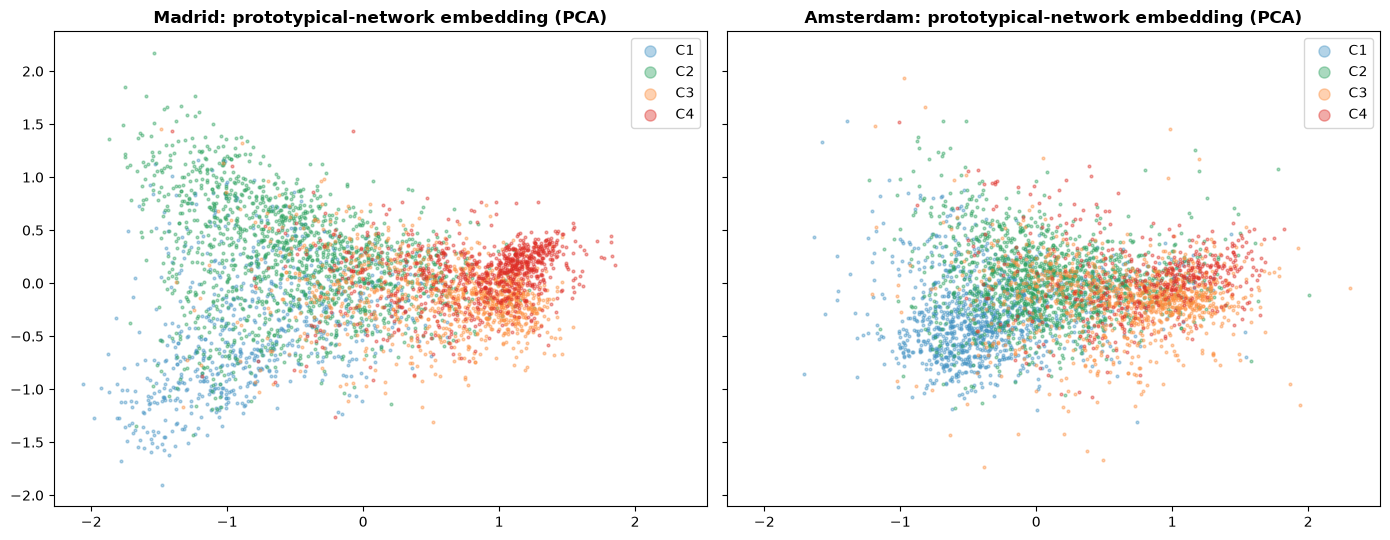

In [21]:
proto_results, Z_EMB = {}, None
if RUN_PROTONET and torch is not None:
    torch.manual_seed(SEED); torch.set_num_threads(N_JOBS)

    class ProtoNet(torch.nn.Module):
        def __init__(self, d_in, d_emb=32):
            super().__init__()
            self.net = torch.nn.Sequential(torch.nn.Linear(d_in, 128), torch.nn.ReLU(), torch.nn.Dropout(0.1),
                                           torch.nn.Linear(128, 64), torch.nn.ReLU(), torch.nn.Linear(64, d_emb))

        def forward(self, x):
            return self.net(x)

    def train_protonet(X_train, y_train, episodes=3000, k_query=20, seed=SEED):
        # Episodic training: every step is a small 4-way few-shot task drawn from Madrid.
        rng = np.random.default_rng(seed)
        Xt = torch.tensor(np.clip(X_train, -8, 8), dtype=torch.float32)
        model = ProtoNet(X_train.shape[1]); opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
        idx = [np.where(y_train == c)[0] for c in range(1, 5)]
        for _ in range(episodes):
            k = int(rng.choice([5, 10, 25]))
            s = [rng.choice(i, k + k_query, replace=False) for i in idx]
            sup = torch.tensor(np.concatenate([a[:k] for a in s])); qry = torch.tensor(np.concatenate([a[k:] for a in s]))
            protos = model(Xt[sup]).view(4, k, -1).mean(1)
            logits = -torch.cdist(model(Xt[qry]), protos) ** 2
            loss = torch.nn.functional.cross_entropy(logits, torch.arange(4).repeat_interleave(k_query))
            opt.zero_grad(); loss.backward(); opt.step()
        return model.eval()

    t0 = time.time()
    protonet = train_protonet(Xm, ym)
    torch.save(protonet.state_dict(), MODEL_DIR / 'nb7_protonet.pt')
    with torch.no_grad():
        Z_EMB = {c: protonet(torch.tensor(np.clip(X[c], -8, 8), dtype=torch.float32)).numpy() for c in CITIES}
    print(f'Prototypical network trained on Madrid in {time.time() - t0:.0f}s')

    def protonet_scores(sup, y_sup, Z=None):
        # Negative squared distance to the class prototypes (mean support embedding per class), scale-free.
        Z = Z_EMB['Amsterdam'] if Z is None else Z
        P = np.stack([Z[sup][y_sup == c].mean(0) for c in range(1, 5)])
        d = -((Z[:, None] - P[None]) ** 2).sum(2)
        return d / (d.std() + 1e-9)

    FEWSHOT = {
        'prototype on raw features (Notebook 4 method)': lambda sup, n: -((Xa[:, None] - np.stack(
            [Xa[sup][ya[sup] == c].mean(0) for c in range(1, 5)])[None]) ** 2).sum(2),
        'prototypical network':                          lambda sup, n: protonet_scores(sup, ya[sup]),
        'prototypical network + spatial smoothing':      lambda sup, n: smooth_scores(protonet_scores(sup, ya[sup]), GRID['Amsterdam']),
        'ours (full pipeline, ensemble Stage 1)':        lambda sup, n: adapt(LOGP[FINAL_STAGE1], Xa, sup, ya[sup], n, GRID['Amsterdam']),
    }
    for name, fn in FEWSHOT.items():
        proto_results[name] = evaluate(fn, ABL_DRAWS)
        print(f'{time.time() - t0:5.0f}s  {name:48s} ' + '  '.join(f'{np.mean(proto_results[name][n]):.3f}' for n in SHOTS))
    proto_table = summarise(proto_results)
    proto_table.to_csv(RESULTS_DIR / 'nb7_fewshot_protonet.csv')
    display(proto_table.style.format('{:.3f}').highlight_max(color='#c7e9c0'))

    # What did the embedding learn? 2-D PCA of the embeddings, coloured by true class, in both cities
    from sklearn.decomposition import PCA
    pca = PCA(2, random_state=SEED).fit(Z_EMB['Madrid'])
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
    rng_pca = np.random.default_rng(SEED)
    for ax, city in zip(axes, CITIES):
        idx = rng_pca.choice(len(Y[city]), 4000, replace=False)
        E = pca.transform(Z_EMB[city][idx])
        for k in range(1, 5):
            sel = Y[city][idx] == k
            ax.scatter(E[sel, 0], E[sel, 1], s=4, alpha=.4, color=CLASS_COLORS[k], label=f'C{k}')
        ax.set_title(f'{city}: prototypical-network embedding (PCA)', fontweight='bold'); ax.legend(markerscale=4)
    plt.tight_layout(); fig.savefig(RESULTS_DIR / 'nb7_protonet_embedding.png', dpi=150, bbox_inches='tight'); plt.show()
else:
    print('Skipped: set RUN_PROTONET = True and install torch to run the prototypical network.')

**Interpretation.** Metric learning is a credible alternative, but it is not the selected model here. On the supplied development results, the raw-feature prototype averages **0.560**, the Madrid-trained prototypical network **0.609**, and the network plus smoothing **0.626**; the full transfer pipeline reaches **0.720** on those same draws. A fixed embedding and class prototypes preserve useful age ordering, but do not adequately recalibrate Amsterdam's shifted spectral levels or use the unlabelled target-city population. Continued boosting adapts the decision boundary as labels arrive, while self-training and spatial context exploit additional Amsterdam-specific evidence. The metric-learning experiment remains a useful comparison, not the final submission.

## 7.20 Idea tournament: every candidate on the same development draws

We collected improvement ideas from our own analysis, from our earlier internal model (LightGBM + RF ensemble, smoothing, self-training: average F1 0.696) and from external suggestions (Meta AI, Gemini). Each is run **on top of our full pipeline** on the same development draws, so the table compares like with like.

| Candidate | Source | Idea |
|---|---|---|
| `ours (ensemble)`, `ours (lgbm)`, `ours (rf)`, … | us | Full pipeline on the ensemble or on a single Stage 1 model (different models can win at different *n*) |
| `ours, no self-training` | us | Self-training is decisive at low *n* but can be neutral at large *n*; per-n selection can switch it off where it does not help |
| `+ Stage 2 seed bagging` | us | Average 5 adaptations with different random seeds (cuts variance at low *n*) |
| `+ per-member adaptation` | us | Adapt each Stage 1 model separately, then average (more diverse corrections) |
| `per-member + equal-count pseudo-labels` | us + Gemini #1 | The two best development ideas combined |
| `+ lp-aware pseudo-labels` | us | Pick pseudo-labels after adding the labelled-neighbour evidence |
| `boundary-matched Stage 1` | us, refining Gemini #4 | Train Madrid with the **target city's** class 1/2 boundary (1945). The boundary is given by the organisers, so no Amsterdam label is used |
| `down-weight Madrid 1945–60` | Gemini #4 | Weight 0.3 on Madrid pixels in the zone where the two cities' boundaries disagree |
| `equal-count pseudo-labels` | Gemini #1, our earlier model | The same number of pseudo-labels per class instead of the top 30% of each class |
| `+ own Madrid probabilities as inputs` | Gemini #2 | The pixel's Stage 1 log-probabilities as extra Stage 2 features |
| `+ density ratio input` | Gemini #3 | Building density 150 m / 330 m as an extra Stage 2 feature |
| `majority filter instead of smoothing` | Meta AI | 3 × 3 hard-label vote in place of probability smoothing |
| `+ EM prior correction` / `per-member + EM prior correction` | us (Saerens et al., 2002) | Re-estimate Amsterdam's class shares from the unlabelled predictions and shift the scores before smoothing. The balanced Stage 1 over-predicts the rare class 4; this matters once the model is well adapted (large *n*) |
| `Stage 1 without spectral level` | us, from section 7.23 | Spectral level is the city-specific family: dropping it from Stage 1 improves zero-shot transfer, while Stage 2 still sees all features |

**Selection without leakage.** The development draws use `SEED + 1`; the final evaluation uses ten fresh draws from `SEED`. For each label budget, the default is per-member adaptation; a challenger is selected only if it beats that default by at least **0.003** on development draws. This yields a budget-aware final procedure:

| Amsterdam labels per class | Selected configuration on development draws | Development macro-F1 |
|---:|---|---:|
| 5 | LightGBM Stage 1 without spectral-level features, then the full Stage 2 | 0.660 |
| 25 | Per-member adaptation + EM prior correction | 0.721 |
| 50 | Per-member adaptation + EM prior correction | 0.733 |
| 100 | Per-member adaptation + EM prior correction | 0.761 |
| 200 | Per-member adaptation + EM prior correction | 0.779 |

Among the fixed tournament candidates, **+ per-member adaptation** has the best average (**0.723**). The selected per-budget procedure is stronger in development because the best choice changes with n: the no-spectral-level Stage 1 is best at n=5, while per-member adaptation + EM prior correction is favored from n=25 onward. This selection rule yields a development mean of about **0.731** across the five budgets; the reported fresh-draw mean is **0.727**.

This is one reproducible **selection rule**, not one frozen configuration for every n. At n=5, omitting spectral-level features from Stage 1 reduces a city-specific brightness shortcut. From n=25 onward, member-specific corrections and class-prior re-estimation win on development draws; the prior estimate is deliberately not selected at n=5, where it is unstable. Fresh final draws are used only to report performance, not to choose configurations.

In [22]:
SELECT_PER_N   = True                        # False = use DEFAULT_CHOICE for every n
DEFAULT_CHOICE = '+ per-member adaptation'   # best average in our development runs
SELECT_MARGIN  = 0.003                       # a challenger must beat the default by this much at that n


def family(name):
    if name.startswith('ctx'):
        return 'spatial context'
    if 'break' in name or 'maxjump' in name:
        return 'construction event'
    if name.endswith('_mean') or '_p19' in name or '_p20' in name:
        return 'spectral level'
    return 'temporal dynamics'


# Feature families (also used in section 7.23)
FAM = np.array([family(f) for f in FEATURE_NAMES])
STAGE1_COLS = {'lgbm_nolevel': np.where(FAM != 'spectral level')[0]}   # Stage 1 variants on a feature subset

# Extra Madrid-trained Stage 1 variants (LightGBM) for the tournament
wmy_m = DATA['Madrid']['wmy']
cw_m = (len(ym) / (4 * np.bincount(ym)[1:]))[ym - 1]
BASES = dict(LOGP)
if RUN_TOURNAMENT:
    t0 = time.time()
    m = lgb.LGBMClassifier(**{**ZOO['lgbm']().get_params(), 'class_weight': None}).fit(
        Xm, ym, sample_weight=cw_m * np.where((wmy_m > 1945) & (wmy_m <= 1960), 0.3, 1.0))
    BASES['lgbm_downweight'] = log_proba(m, Xa); m.booster_.save_model(str(MODEL_DIR / 'nb7_stage1_lgbm_downweight.txt'))
    ym_match = age_class(wmy_m, 'Amsterdam')          # Madrid labels cut at the TARGET city's class 1/2 boundary
    m = ZOO['lgbm']().fit(Xm, ym_match)
    BASES['lgbm_match'] = log_proba(m, Xa); m.booster_.save_model(str(MODEL_DIR / 'nb7_stage1_lgbm_match.txt'))
    # Spectral level is the city-specific family (section 7.23): a Stage 1 without it transfers better zero-shot;
    # Stage 2 still sees all features
    cols = STAGE1_COLS['lgbm_nolevel']
    m = ZOO['lgbm']().fit(Xm[:, cols], ym)
    BASES['lgbm_nolevel'] = log_proba(m, Xa[:, cols]); m.booster_.save_model(str(MODEL_DIR / 'nb7_stage1_lgbm_nolevel.txt'))
    del m; gc.collect()
    print(f'Extra Stage 1 variants trained in {time.time() - t0:.0f}s')
    for k in ('lgbm_downweight', 'lgbm_match', 'lgbm_nolevel'):
        print(f'  zero-shot {k:16s} {f1_score(ya, BASES[k].argmax(1) + 1, average="macro"):.4f}')

dens = FEAT['Amsterdam'][['ctx2_density', 'ctx5_density']].values
EXTRA_INPUTS = {'density_ratio': (dens[:, :1] / np.maximum(dens[:, 1:], 1e-3)).astype(np.float32)}


def run_spec(spec, sup, y_sup, n, bases=None, X_city=None, extra=None, grid=None):
    # One Stage 2 configuration. spec keys: bases (list of Stage 1 keys; >1 = per-member adaptation),
    # seeds (number of Stage 2 seeds), inputs ('plain' | 'own_probs' | 'density_ratio'), cfg (Stage 2 options),
    # post (None | 'majority').
    bases = BASES if bases is None else bases
    X_city = Xa if X_city is None else X_city
    extra = EXTRA_INPUTS if extra is None else extra
    grid = GRID['Amsterdam'] if grid is None else grid
    b = [bases[k] for k in spec['bases']]
    if spec['inputs'] == 'own_probs':
        X_in = np.hstack([X_city, b[0].astype(np.float32)])
    elif spec['inputs'] == 'plain':
        X_in = X_city
    else:
        X_in = np.hstack([X_city, extra[spec['inputs']]])
    if len(b) == 1 and spec['seeds'] == 1:
        S = adapt(b[0], X_in, sup, y_sup, n, grid, spec['cfg'])
    else:
        S = adapt_bagged(b, X_in, sup, y_sup, n, grid, spec['cfg'], seeds=tuple(SEED + i for i in range(spec['seeds'])))
    return majority_filter(S, grid) if spec['post'] == 'majority' else S


def spec(bases=(FINAL_STAGE1,), seeds=1, inputs='plain', post=None, **cfg):
    return dict(bases=list(bases), seeds=seeds, inputs=inputs, cfg=cfg, post=post)


DEFAULT_SPEC = spec()
CANDIDATES = {
    'ours (ensemble)':                         DEFAULT_SPEC,
    **{f'ours ({m})': spec(bases=[m]) for m in STAGE1_MODELS},
    'ours, no self-training':                  spec(self_train=0),
    'per-member + equal-count pseudo-labels':  spec(bases=STAGE1_MODELS, pseudo_equal=True),
    '+ Stage 2 seed bagging (5)':              spec(seeds=5),
    '+ per-member adaptation':                 spec(bases=STAGE1_MODELS),
    '+ EM prior correction':                   spec(em_prior=1.0),
    'per-member + EM prior correction':        spec(bases=STAGE1_MODELS, em_prior=1.0),
    '+ lp-aware pseudo-labels':                spec(lp_pseudo=True),
    'equal-count pseudo-labels (Gemini #1)':   spec(pseudo_equal=True),
    '+ own Madrid probs as inputs (Gemini #2)': spec(inputs='own_probs'),
    '+ density ratio input (Gemini #3)':       spec(inputs='density_ratio'),
    'majority filter, no smoothing (Meta AI)': spec(post='majority', smooth=False),
}
if RUN_TOURNAMENT:
    CANDIDATES['boundary-matched Stage 1 (lgbm)'] = spec(bases=['lgbm_match'])
    CANDIDATES['down-weight Madrid 1945-60 (lgbm, Gemini #4)'] = spec(bases=['lgbm_downweight'])
    CANDIDATES['Stage 1 without spectral level (lgbm)'] = spec(bases=['lgbm_nolevel'])

tournament = {}
if RUN_TOURNAMENT:
    t0 = time.time()
    for name, sp in CANDIDATES.items():
        tournament[name] = evaluate(lambda sup, n, sp=sp: run_spec(sp, sup, ya[sup], n), ABL_DRAWS)
        print(f'{time.time() - t0:5.0f}s  {name:46s} ' + '  '.join(f'{np.mean(tournament[name][n]):.3f}' for n in SHOTS))
    tour_table = summarise(tournament).sort_values('avg F1 (prize)', ascending=False)
    tour_table.to_csv(RESULTS_DIR / 'nb7_tournament.csv')
    display(tour_table.style.format('{:.3f}').highlight_max(color='#c7e9c0'))

# The rule used by the final model: per n, the default unless a challenger beats it by SELECT_MARGIN
CHOSEN = {n: DEFAULT_CHOICE for n in SHOTS}
if RUN_TOURNAMENT and SELECT_PER_N:
    for n in SHOTS:
        best = max(tournament, key=lambda k: np.mean(tournament[k][n]))
        if np.mean(tournament[best][n]) - np.mean(tournament[DEFAULT_CHOICE][n]) >= SELECT_MARGIN:
            CHOSEN[n] = best
display(pd.DataFrame({'configuration used': CHOSEN,
                      'development F1': {n: np.mean(tournament[CHOSEN[n]][n]) for n in SHOTS} if tournament else {},
                      'default F1': {n: np.mean(tournament[DEFAULT_CHOICE][n]) for n in SHOTS} if tournament else {}}))

Extra Stage 1 variants trained in 42s
  zero-shot lgbm_downweight  0.4828
  zero-shot lgbm_match       0.4396
  zero-shot lgbm_nolevel     0.5715
   50s  ours (ensemble)                                0.649  0.712  0.721  0.751  0.768
  100s  ours (lgbm)                                    0.642  0.705  0.717  0.750  0.767
  151s  ours (rf)                                      0.644  0.710  0.721  0.750  0.769
  202s  ours (cat)                                     0.657  0.704  0.719  0.749  0.768
  252s  ours (et)                                      0.627  0.710  0.721  0.751  0.768
  269s  ours, no self-training                         0.619  0.706  0.718  0.747  0.767
  456s  per-member + equal-count pseudo-labels         0.658  0.712  0.721  0.751  0.769
  709s  + Stage 2 seed bagging (5)                     0.650  0.713  0.721  0.752  0.769
  915s  + per-member adaptation                        0.651  0.715  0.724  0.753  0.771
  967s  + EM prior correction                        

,n=5,n=25,n=50,n=100,n=200,avg F1 (prize),low-data n=25 (prize),peak F1 (prize)
+ per-member adaptation,0.651,0.715,0.724,0.753,0.771,0.723,0.715,0.771
per-member + equal-count pseudo-labels,0.658,0.712,0.721,0.751,0.769,0.722,0.712,0.769
+ lp-aware pseudo-labels,0.651,0.712,0.721,0.751,0.770,0.721,0.712,0.770
+ Stage 2 seed bagging (5),0.650,0.713,0.721,0.752,0.769,0.721,0.713,0.769
+ own Madrid probs as inputs (Gemini #2),0.646,0.714,0.721,0.751,0.770,0.721,0.714,0.770
+ density ratio input (Gemini #3),0.650,0.713,0.720,0.750,0.769,0.720,0.713,0.769
ours (ensemble),0.649,0.712,0.721,0.751,0.768,0.720,0.712,0.768
equal-count pseudo-labels (Gemini #1),0.654,0.709,0.718,0.749,0.767,0.720,0.709,0.767
ours (cat),0.657,0.704,0.719,0.749,0.768,0.719,0.704,0.768
ours (rf),0.644,0.710,0.721,0.750,0.769,0.719,0.710,0.769


,configuration used,development F1,default F1
5,Stage 1 without spectral level (lgbm),0.660155,0.650804
25,per-member + EM prior correction,0.721351,0.714555
50,per-member + EM prior correction,0.732568,0.724262
100,per-member + EM prior correction,0.761408,0.753306
200,per-member + EM prior correction,0.778779,0.771089


## 7.21 Final results (`N_TRIALS` fresh draws per *n*)

The selected final system is **budget-aware**. Its usual Stage 1 base is a Madrid-trained ensemble of LightGBM, Random Forest, CatBoost, and Extra Trees. Stage 2 uses Amsterdam support labels for continued boosting, with capacity scaled to n, prediction context, one round of confident pseudo-labelling, spatial probability smoothing, and label propagation. The development tournament selects the configuration per n: no-spectral-level LightGBM at n=5, and per-member adaptation plus EM prior correction at n=25, 50, 100, and 200.

**Why this is the final choice:** it uses both kinds of target-city information allowed by the challenge. Support labels calibrate city-specific boundaries; unlabelled Amsterdam pixels inform self-training and, at larger n, the class prior. Spatial context is included because age is strongly clustered, while temporal and change-point features retain evidence about when construction occurred. No single component is expected to solve domain shift alone.

The development draws use `SEED + 1`; these reported scores use **ten fresh draws** from `SEED`, with each draw evaluated only on Amsterdam pixels outside its support set. The same-draw comparison with Notebook 5 is reported separately.

In [23]:
METRIC_FNS = {'macro-F1': lambda t, p: f1_score(t, p, average='macro'),
              'accuracy': accuracy_score,
              'balanced accuracy': balanced_accuracy_score,
              'weighted F1': lambda t, p: f1_score(t, p, average='weighted')}


def evaluate_metrics(method, draws, y=ya):
    # Like evaluate(), but records every metric in METRIC_FNS: {metric: {n: [score per draw]}}.
    out = {m: {n: [] for n in draws} for m in METRIC_FNS}
    for n, sups in draws.items():
        for sup in sups:
            q = np.ones(len(y), bool); q[sup] = False
            pred = method(sup, n)[q].argmax(1) + 1
            for m, fn in METRIC_FNS.items():
                out[m][n].append(fn(y[q], pred))
    return out


FINAL_DRAWS = support_draws(ya, trials=N_TRIALS)
t0 = time.time()
METRICS = evaluate_metrics(lambda sup, n: run_spec(CANDIDATES[CHOSEN[n]], sup, ya[sup], n), FINAL_DRAWS)
final = {'Ours (Notebook 7)': METRICS['macro-F1']}
print(f'Final evaluation done in {time.time() - t0:.0f}s')

# Paired comparison: Notebook 5's pipeline on the very same draws (needs the no-season-filter Stage 1 from 7.18)
if 'base_all' in globals():
    nb5_same = evaluate(lambda sup, n: adapt(base_all, X_all['Amsterdam'], sup, ya[sup], n, GRID['Amsterdam'], OFF), FINAL_DRAWS)
    paired = {f'n = {n}': f"{np.mean(np.subtract(final['Ours (Notebook 7)'][n], nb5_same[n])):+.3f}  "
                          f"({int((np.subtract(final['Ours (Notebook 7)'][n], nb5_same[n]) > 0).sum())}/{len(nb5_same[n])} wins)"
              for n in SHOTS}
    display(pd.Series(paired, name='Ours minus Notebook 5, same draws').to_frame().T)

res = final['Ours (Notebook 7)']
f1_zero = f1_score(ya, LOGP[FINAL_STAGE1].argmax(1) + 1, average='macro')
results_table = pd.DataFrame({
    'Notebook 4 baseline': [f"{BASELINE['zero-shot']:.3f}"] + [f'{BASELINE[n]:.3f}' for n in SHOTS]
                           + [f'{np.mean([BASELINE[n] for n in SHOTS]):.3f}'],
    'Notebook 5':          [f"{NB5['zero-shot']:.3f}"] + [f'{NB5[n]:.3f}' for n in SHOTS]
                           + [f'{np.mean([NB5[n] for n in SHOTS]):.3f}'],
    'Earlier internal model': [f"{EARLIER['zero-shot']:.3f}"] + [f'{EARLIER[n]:.3f}' for n in SHOTS]
                              + [f'{np.mean([EARLIER[n] for n in SHOTS]):.3f}'],
    'Ours (Notebook 7)':   [f'{f1_zero:.3f}'] + [f'{np.mean(res[n]):.3f} ± {np.std(res[n]):.3f}' for n in SHOTS]
                           + [f'{np.mean([np.mean(res[n]) for n in SHOTS]):.3f}'],
}, index=['zero-shot'] + [f'n = {n}' for n in SHOTS] + ['Average F1'])
results_table.loc['Madrid spatial CV'] = ['—', '0.647 ± 0.009', '—',
                                          f'{CV_F1[FINAL_STAGE1].mean():.3f} ± {CV_F1[FINAL_STAGE1].std():.3f}']
display(results_table)

# Every metric, mean ± std over the draws (the prizes use macro-F1; accuracy is shown for completeness)
zero_pred = LOGP[FINAL_STAGE1].argmax(1) + 1
oof_pred = OOF[FINAL_STAGE1].argmax(1) + 1
metrics_table = pd.DataFrame(
    {m: [f'{METRIC_FNS[m](ya, zero_pred):.3f}']
        + [f'{np.mean(METRICS[m][n]):.3f} ± {np.std(METRICS[m][n]):.3f}' for n in SHOTS]
        + [f'{np.mean([np.mean(METRICS[m][n]) for n in SHOTS]):.3f}', f'{max(np.mean(METRICS[m][n]) for n in SHOTS):.3f}']
        + [f"{np.mean([METRIC_FNS[m](ym[va], oof_pred[va]) for _, va in folds]):.3f} ± "
           f"{np.std([METRIC_FNS[m](ym[va], oof_pred[va]) for _, va in folds]):.3f}"]
     for m in METRIC_FNS},
    index=['Amsterdam zero-shot'] + [f'Amsterdam n = {n}' for n in SHOTS] + ['average over n', 'peak over n', 'Madrid spatial CV'])
display(metrics_table.style.set_caption('Ours (Notebook 7): all metrics'))
print(f"Prize metrics -> average F1 {np.mean([np.mean(res[n]) for n in SHOTS]):.3f} | "
      f"peak F1 {max(np.mean(res[n]) for n in SHOTS):.3f} | low-data (n=25) F1 {np.mean(res[25]) if 25 in res else float('nan'):.3f}")

# Machine-readable summary for the slides and documents
SUMMARY = {
    'shots': SHOTS, 'n_trials': N_TRIALS, 'zero_shot': float(f1_zero),
    'mean': {str(n): float(np.mean(res[n])) for n in SHOTS}, 'std': {str(n): float(np.std(res[n])) for n in SHOTS},
    'madrid_cv_mean': float(CV_F1[FINAL_STAGE1].mean()), 'madrid_cv_std': float(CV_F1[FINAL_STAGE1].std()),
    'chosen': {str(n): CHOSEN[n] for n in SHOTS},
    'baseline': {str(k): v for k, v in BASELINE.items()}, 'nb5': {str(k): v for k, v in NB5.items()},
    'earlier': {str(k): v for k, v in EARLIER.items()},
    'metrics': {m: {'mean': {str(n): float(np.mean(METRICS[m][n])) for n in SHOTS},
                    'std': {str(n): float(np.std(METRICS[m][n])) for n in SHOTS},
                    'zero_shot': float(METRIC_FNS[m](ya, zero_pred))} for m in METRIC_FNS},
}
if 'nb5_same' in globals():
    SUMMARY['paired_vs_nb5'] = {str(n): {'diff': float(np.mean(np.subtract(res[n], nb5_same[n]))),
                                         'wins': int((np.subtract(res[n], nb5_same[n]) > 0).sum()),
                                         'draws': len(res[n])} for n in SHOTS}
json.dump(SUMMARY, open(RESULTS_DIR / 'nb7_summary.json', 'w'), indent=2)
print('Saved', RESULTS_DIR / 'nb7_summary.json')

Final evaluation done in 386s


,n = 5,n = 25,n = 50,n = 100,n = 200
"Ours minus Notebook 5, same draws",+0.099 (10/10 wins),+0.058 (10/10 wins),+0.049 (10/10 wins),+0.049 (10/10 wins),+0.048 (10/10 wins)


,Notebook 4 baseline,Notebook 5,Earlier internal model,Ours (Notebook 7)
zero-shot,0.343,0.530,0.559,0.564
n = 5,0.544,0.557,0.613,0.656 ± 0.016
n = 25,0.599,0.650,0.688,0.708 ± 0.017
n = 50,0.608,0.680,0.704,0.729 ± 0.016
n = 100,0.613,0.714,0.731,0.763 ± 0.007
n = 200,0.615,0.731,0.746,0.779 ± 0.005
Average F1,0.596,0.666,0.696,0.727
Madrid spatial CV,—,0.647 ± 0.009,—,0.644 ± 0.009


,macro-F1,accuracy,balanced accuracy,weighted F1
Amsterdam zero-shot,0.564,0.565,0.613,0.559
Amsterdam n = 5,0.656 ± 0.016,0.660 ± 0.017,0.681 ± 0.013,0.663 ± 0.018
Amsterdam n = 25,0.708 ± 0.017,0.718 ± 0.017,0.711 ± 0.016,0.718 ± 0.018
Amsterdam n = 50,0.729 ± 0.016,0.736 ± 0.017,0.731 ± 0.015,0.736 ± 0.018
Amsterdam n = 100,0.763 ± 0.007,0.766 ± 0.006,0.762 ± 0.005,0.767 ± 0.006
Amsterdam n = 200,0.779 ± 0.005,0.783 ± 0.004,0.781 ± 0.005,0.783 ± 0.004
average over n,0.727,0.733,0.733,0.733
peak over n,0.779,0.783,0.781,0.783
Madrid spatial CV,0.644 ± 0.009,0.652 ± 0.007,0.641 ± 0.012,0.650 ± 0.008


Prize metrics -> average F1 0.727 | peak F1 0.779 | low-data (n=25) F1 0.708
Saved results/nb7_summary.json


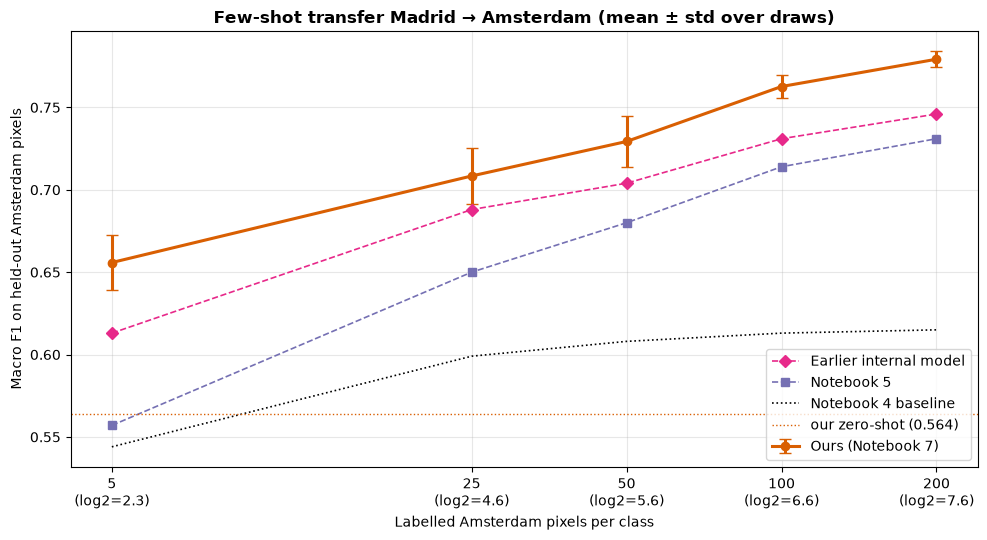

In [24]:
# Required submission plot: F1 (± std) against log2(sample size)
fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.log2(SHOTS)
ax.errorbar(x, [np.mean(res[n]) for n in SHOTS], yerr=[np.std(res[n]) for n in SHOTS], fmt='o-', color='#d95f02',
            capsize=4, lw=2.2, label='Ours (Notebook 8)')
ax.plot(x, [EARLIER[n] for n in SHOTS], 'D--', color='#e7298a', lw=1.2, label='Earlier internal model')
ax.plot(x, [NB5[n] for n in SHOTS], 's--', color='#7570b3', lw=1.2, label='Notebook 5')
ax.plot(x, [BASELINE[n] for n in SHOTS], 'k:', lw=1.2, label='Notebook 4 baseline')
ax.axhline(f1_zero, color='#d95f02', ls=':', lw=1, label=f'our zero-shot ({f1_zero:.3f})')
ax.set_xticks(x); ax.set_xticklabels([f'{n}\n(log2={np.log2(n):.1f})' for n in SHOTS])
ax.set_xlabel('Labelled Amsterdam pixels per class'); ax.set_ylabel('Macro F1 on held-out Amsterdam pixels')
ax.set_title('Few-shot transfer Madrid → Amsterdam (mean ± std over draws)', fontweight='bold')
ax.grid(alpha=.3); ax.legend(loc='lower right')
plt.tight_layout(); fig.savefig(RESULTS_DIR / 'nb7_f1_vs_log2n.png', dpi=150, bbox_inches='tight'); plt.show()

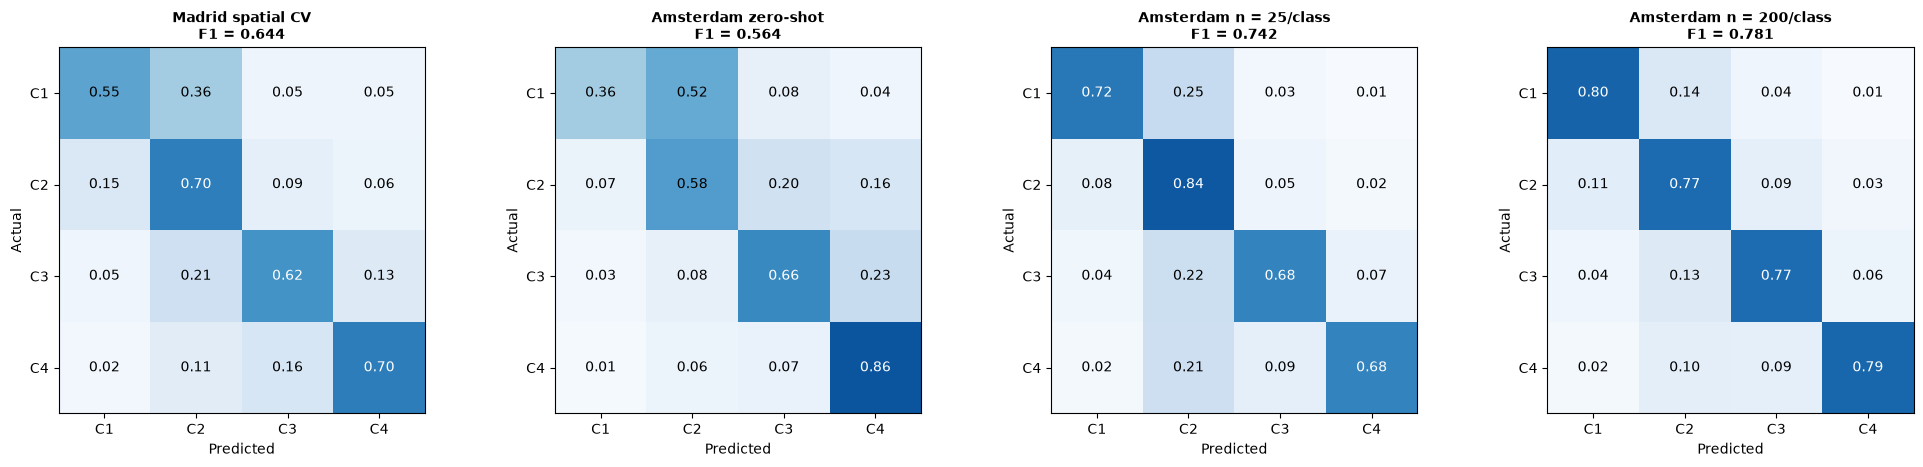

,Class 1,Class 2,Class 3,Class 4
n = 25,0.776,0.737,0.748,0.705
n = 200,0.815,0.764,0.780,0.764


In [25]:
# Confusion matrices: Madrid CV (deliverable), Amsterdam zero-shot, and adapted models at n = 25 and 200
show_n = [n for n in (25, 200) if n in SHOTS]
fig, axes = plt.subplots(1, 2 + len(show_n), figsize=(5 * (2 + len(show_n)), 4.6))
plot_cm(axes[0], ym, OOF[FINAL_STAGE1].argmax(1) + 1, f'Madrid spatial CV\nF1 = {CV_F1[FINAL_STAGE1].mean():.3f}')
plot_cm(axes[1], ya, LOGP[FINAL_STAGE1].argmax(1) + 1, f'Amsterdam zero-shot\nF1 = {f1_zero:.3f}')
per_class = {}
for ax, n in zip(axes[2:], show_n):
    sup = FINAL_DRAWS[n][0]
    q = np.ones(len(ya), bool); q[sup] = False
    pred = run_spec(CANDIDATES[CHOSEN[n]], sup, ya[sup], n).argmax(1) + 1
    plot_cm(ax, ya[q], pred[q], f'Amsterdam n = {n}/class\nF1 = {f1_score(ya[q], pred[q], average="macro"):.3f}')
    per_class[f'n = {n}'] = f1_score(ya[q], pred[q], average=None)
plt.tight_layout(); fig.savefig(RESULTS_DIR / 'nb7_confusion.png', dpi=150, bbox_inches='tight'); plt.show()
SUMMARY['per_class'] = {k: [float(x) for x in v] for k, v in per_class.items()}
json.dump(SUMMARY, open(RESULTS_DIR / 'nb7_summary.json', 'w'), indent=2)
display(pd.DataFrame(per_class, index=[f'Class {k}' for k in range(1, 5)]).T.style.format('{:.3f}')
        .background_gradient(cmap='Greens', axis=None).set_caption('Per-class F1 on held-out Amsterdam pixels'))

## 7.22 Where are the errors? A map of the adapted predictions

Errors that cluster in space point to neighbourhood-level confusion (e.g. a whole renovated district), not pixel noise.

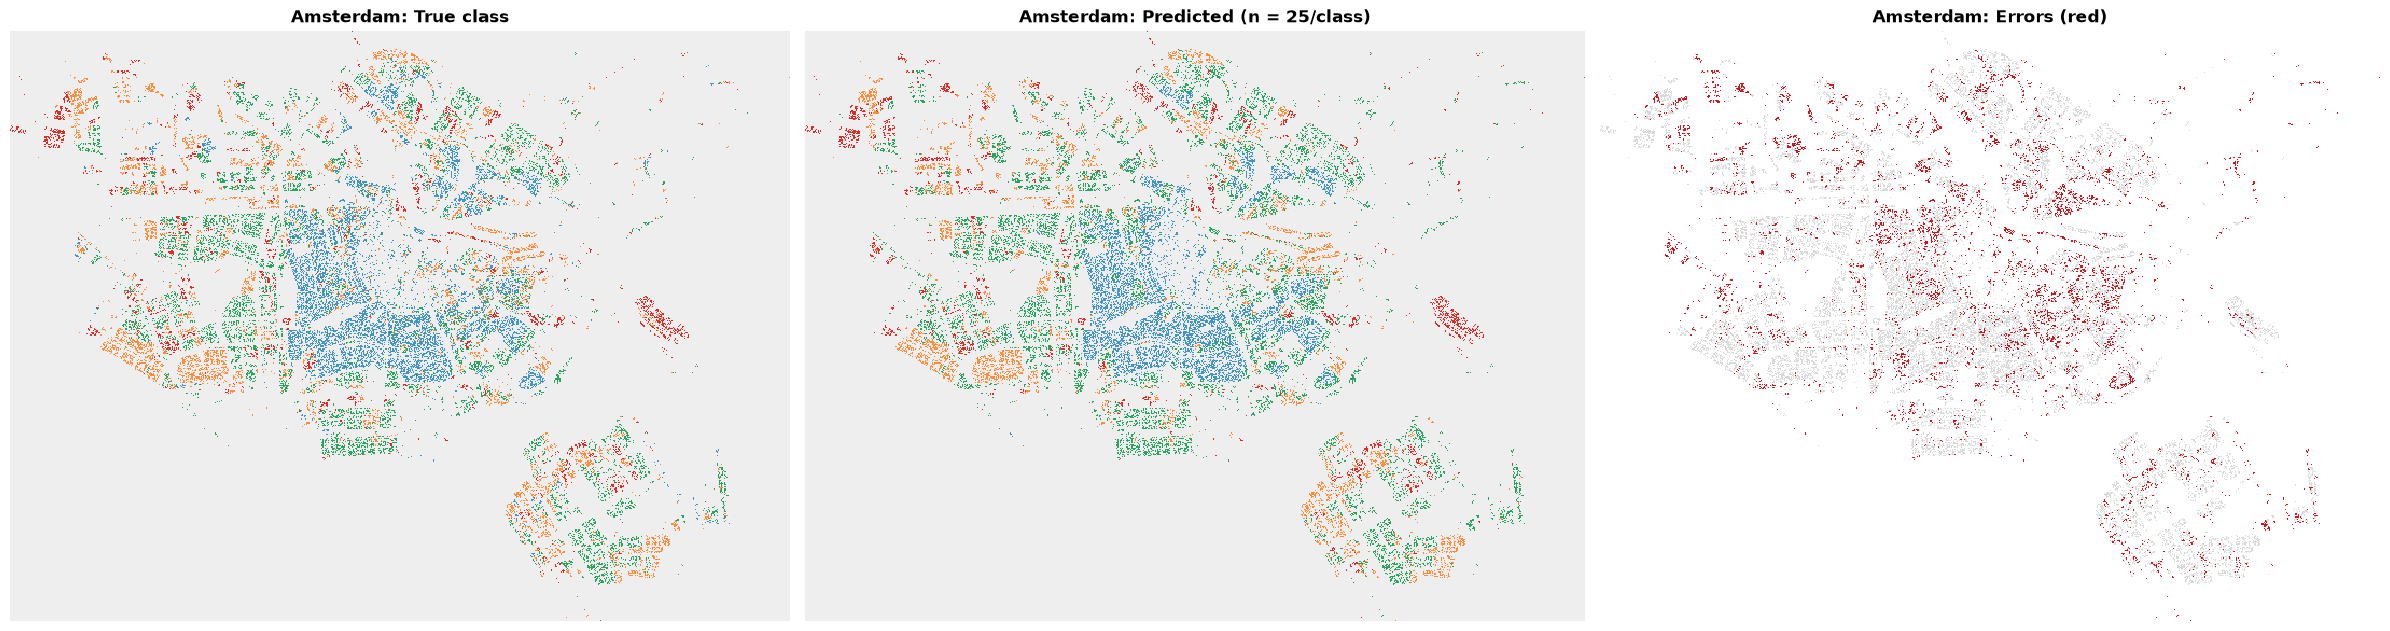

In [26]:
n_map = 25 if 25 in SHOTS else SHOTS[0]
sup = FINAL_DRAWS[n_map][0]
pred = run_spec(CANDIDATES[CHOSEN[n_map]], sup, ya[sup], n_map).argmax(1) + 1
d = DATA['Amsterdam']
fig, axes = plt.subplots(1, 3, figsize=(24, 8))
axes[0].imshow(to_grid(d, ya.astype(float)), cmap=cmap, vmin=.5, vmax=4.5, interpolation='nearest')
axes[1].imshow(to_grid(d, pred.astype(float)), cmap=cmap, vmin=.5, vmax=4.5, interpolation='nearest')
axes[2].imshow(to_grid(d, (pred != ya).astype(float)), cmap=ListedColormap(['#d9d9d9', '#cb181d']), interpolation='nearest')
for ax, t in zip(axes, ['True class', f'Predicted (n = {n_map}/class)', 'Errors (red)']):
    ax.set_title(f'Amsterdam: {t}', fontweight='bold'); ax.axis('off')
plt.tight_layout(); plt.show()

## 7.23 What drives the predictions? Spectral, temporal or spatial?

We answer this in three complementary ways, using the LightGBM member of Stage 1 (fast and has exact SHAP values):

1. **SHAP by feature family.** Mean |SHAP| contribution of each family, in Madrid and in Amsterdam. A family that matters in Madrid but not in Amsterdam did not transfer.
2. **SHAP by channel.** Which bands and indices carry the signal.
3. **Group-drop ablation.** Retrain Stage 1 **without** one family and rerun the full Stage 2. SHAP shows what the model *uses*; the ablation shows what it *needs* (correlated families can stand in for each other).

| Family | Features | Signal type |
|---|---|---|
| spectral level | channel means, period means | **spectral**: what the pixel looks like |
| temporal dynamics | std, slope, late − early, year-on-year change, stability | **temporal**: how it changes |
| construction event | change-point year / strength / jumps, largest jump | **temporal**: when it was built |
| spatial context | neighbourhood means (150 m, 330 m), building density | **spatial** |

In Stage 2 the **spatial** signal also enters through smoothing, prediction context and label propagation; the last ablation row switches all of those off as well.

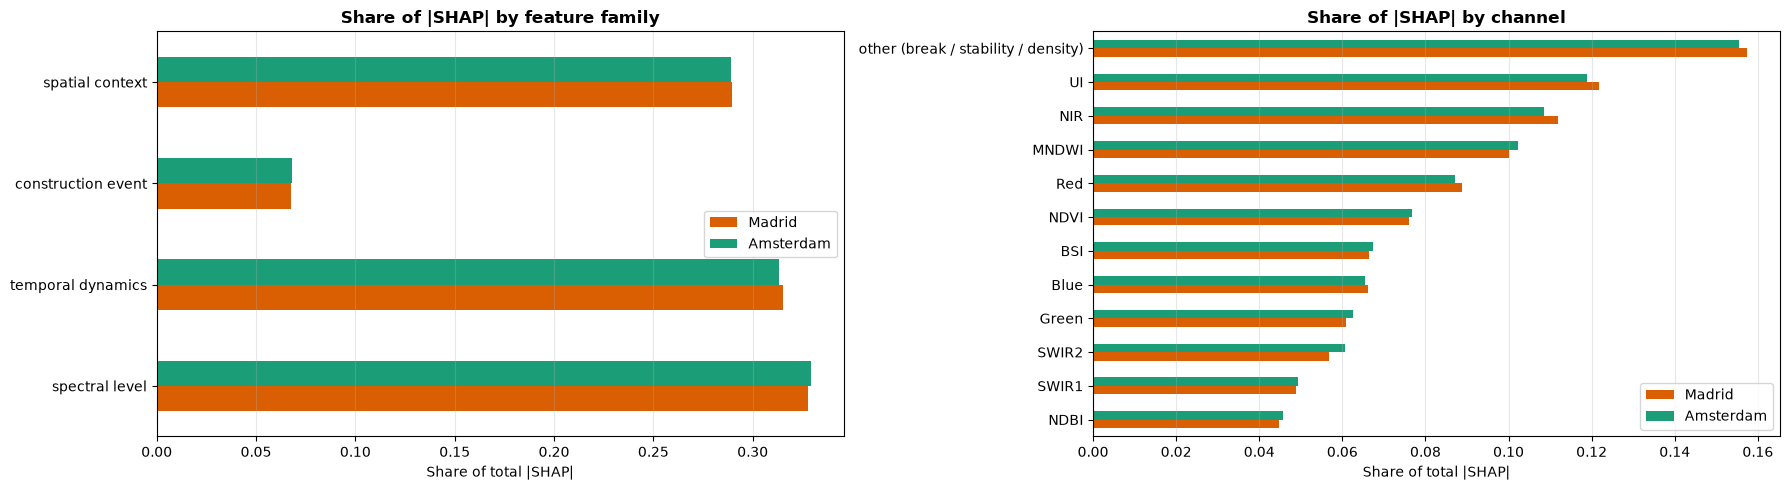

,Madrid,Amsterdam
spectral level,32.8%,32.9%
temporal dynamics,31.5%,31.3%
construction event,6.7%,6.8%
spatial context,29.0%,28.9%


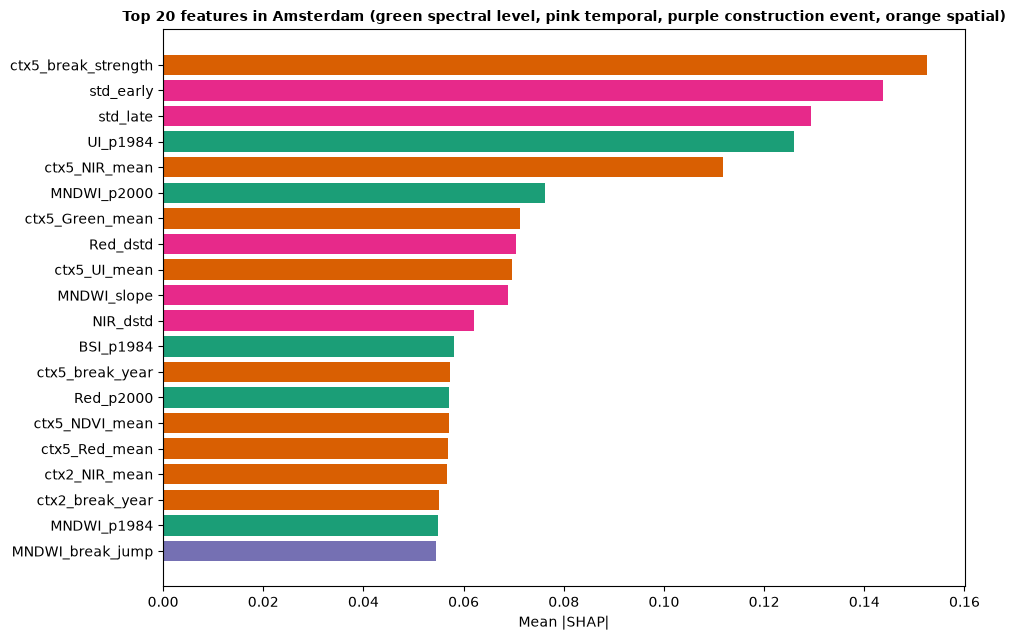

In [27]:
def channel(name):
    parts = name.split('_')
    tok = parts[1] if name.startswith('ctx') else parts[0]
    return tok if tok in CHANNELS else 'other (break / stability / density)'


FAMILIES = ['spectral level', 'temporal dynamics', 'construction event', 'spatial context']
FAM = np.array([family(f) for f in FEATURE_NAMES])
CHAN = np.array([channel(f) for f in FEATURE_NAMES])
lgbm_booster = lgb.Booster(model_file=str(MODEL_DIR / 'nb7_stage1_lgbm.txt'))
rng_shap = np.random.default_rng(SEED)
shap_fam, shap_chan = {}, {}
for city in CITIES:
    idx = rng_shap.choice(len(X[city]), 5000, replace=False)
    contrib = lgbm_booster.predict(X[city][idx], pred_contrib=True).reshape(len(idx), 4, -1)[:, :, :-1]
    imp = pd.Series(np.abs(contrib).mean((0, 1)), index=FEATURE_NAMES)
    shap_fam[city] = imp.groupby(FAM).sum() / imp.sum()
    shap_chan[city] = imp.groupby(CHAN).sum() / imp.sum()
shap_fam = pd.DataFrame(shap_fam).loc[FAMILIES]
shap_chan = pd.DataFrame(shap_chan).sort_values('Amsterdam', ascending=True)
shap_fam.to_csv(RESULTS_DIR / 'nb7_shap_family.csv'); shap_chan.to_csv(RESULTS_DIR / 'nb7_shap_channel.csv')

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
shap_fam.plot.barh(ax=axes[0], color=[CITY_COLORS[c] for c in CITIES])
axes[0].set_title('Share of |SHAP| by feature family', fontweight='bold'); axes[0].set_xlabel('Share of total |SHAP|')
shap_chan.plot.barh(ax=axes[1], color=[CITY_COLORS[c] for c in CITIES])
axes[1].set_title('Share of |SHAP| by channel', fontweight='bold'); axes[1].set_xlabel('Share of total |SHAP|')
for ax in axes: ax.grid(alpha=.3, axis='x')
plt.tight_layout(); plt.show()
display(shap_fam.style.format('{:.1%}').set_caption('Share of |SHAP| per family'))

top = pd.Series(np.abs(lgbm_booster.predict(Xa[:5000], pred_contrib=True).reshape(5000, 4, -1)[:, :, :-1]).mean((0, 1)),
                index=FEATURE_NAMES).sort_values(ascending=False).head(20)[::-1]
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(top.index, top.values, color=[{'spatial context': '#d95f02', 'construction event': '#7570b3',
                                       'spectral level': '#1b9e77', 'temporal dynamics': '#e7298a'}[family(f)] for f in top.index])
ax.set_title('Top 20 features in Amsterdam (green spectral level, pink temporal, purple construction event, orange spatial)',
             fontweight='bold', fontsize=10)
ax.set_xlabel('Mean |SHAP|'); plt.tight_layout(); plt.show()

In [28]:
# Group-drop ablation: retrain the LightGBM Stage 1 without one family, rerun the full Stage 2
IMP_DRAWS = {n: v for n, v in ABL_DRAWS.items() if n in (25, 200)}
NO_SPATIAL_STAGE2 = dict(smooth=False, context=False, label_prop=0)


def group_drop(cols, cfg=None):
    m = ZOO['lgbm']().fit(Xm[:, cols], ym)
    base = log_proba(m, Xa[:, cols]); del m
    r = evaluate(lambda sup, n: adapt(base, Xa[:, cols], sup, ya[sup], n, GRID['Amsterdam'], cfg or {}), IMP_DRAWS)
    return {'zero-shot': f1_score(ya, base.argmax(1) + 1, average='macro'),
            **{f'n={n}': np.mean(v) for n, v in r.items()}}


drop = {}
if RUN_IMPORTANCE:
    t0 = time.time()
    all_cols = np.arange(len(FEATURE_NAMES))
    drop['all features (reference)'] = group_drop(all_cols)
    for f in FAMILIES:
        drop[f'without {f}'] = group_drop(np.where(FAM != f)[0])
    drop['spectral only (no temporal, no spatial)'] = group_drop(np.where(FAM == 'spectral level')[0], NO_SPATIAL_STAGE2)
    drop['no spatial anywhere (features + Stage 2)'] = group_drop(np.where(FAM != 'spatial context')[0], NO_SPATIAL_STAGE2)
    drop_table = pd.DataFrame(drop).T
    drop_table.to_csv(RESULTS_DIR / 'nb7_group_drop.csv')
    ref = drop_table.loc['all features (reference)']
    display(drop_table.style.format('{:.3f}').set_caption('Group-drop ablation (LightGBM Stage 1 + full Stage 2)'))
    display((drop_table - ref).drop('all features (reference)').style.format('{:+.3f}')
            .background_gradient(cmap='Reds_r', axis=None).set_caption('Change vs all features (negative = the family was needed)'))
    print(f'Group-drop done in {time.time() - t0:.0f}s')

,zero-shot,n=25,n=200
all features (reference),0.537,0.705,0.767
without spectral level,0.571,0.706,0.760
without temporal dynamics,0.511,0.694,0.758
without construction event,0.547,0.707,0.766
without spatial context,0.474,0.704,0.760
"spectral only (no temporal, no spatial)",0.435,0.625,0.693
no spatial anywhere (features + Stage 2),0.474,0.666,0.718


,zero-shot,n=25,n=200
without spectral level,+0.035,+0.000,-0.007
without temporal dynamics,-0.025,-0.011,-0.009
without construction event,+0.010,+0.002,-0.001
without spatial context,-0.063,-0.002,-0.007
"spectral only (no temporal, no spatial)",-0.102,-0.081,-0.074
no spatial anywhere (features + Stage 2),-0.063,-0.040,-0.049


Group-drop done in 275s


**How to read this**

* A family with a **large SHAP share** is used a lot; a family whose removal causes a **large F1 drop** is *needed*. If SHAP is large but the drop is small, other families carry the same information.
* Comparing the Madrid and Amsterdam SHAP bars shows which signals **transfer**: a family whose share shrinks in Amsterdam is something Madrid relied on that does not carry over.
* The last two rows answer the headline question directly: how far do we get with **spectral information only**, and how much is lost when **every spatial component** (context features, smoothing, prediction context, label propagation) is removed.

## 7.24 Reusable transfer procedure

`adapt_to_city(n)` is the parameterised transfer procedure required. It:

1. picks the Stage 2 configuration for this *n* (the per-n rule from section 7.20; for an *n* not in `SHOTS`, the rule of the nearest *n* on a log scale),
2. loads the saved Madrid Stage 1 models that configuration needs and scores the target city (its features must be built with sections 7.4–7.11),
3. draws `n` labelled pixels per class with a fixed seed and runs Stage 2,
4. returns the predicted class of **every** pixel and the macro-F1 on the pixels that were not labelled.

For a new city, pass its own `X_city`, `y_city` (only the drawn support labels are used for fitting), feature table and pixel coordinates. If the rule selects the boundary-matched Stage 1, retrain that one model on Madrid with the new city's class 1/2 boundary first (one line in section 7.20).

In [29]:
import joblib


def load_stage1_model(key):
    if key.startswith('lgbm'):
        return lgb.Booster(model_file=str(MODEL_DIR / f'nb7_stage1_{key}.txt'))
    if key == 'cat':
        return CatBoostClassifier().load_model(str(MODEL_DIR / 'nb7_stage1_cat.cbm'))
    return joblib.load(MODEL_DIR / f'nb7_stage1_{key}.joblib')


def city_bases(keys, X_city):
    # Stage 1 log-probabilities of the target city for every Stage 1 key (single model or ensemble) needed.
    singles = sorted({m for k in keys for m in ENSEMBLES.get(k, [k])})
    scores = {}
    for m in singles:
        model = load_stage1_model(m)
        Xc = X_city[:, STAGE1_COLS[m]] if m in STAGE1_COLS else X_city
        p = model.predict(Xc) if m.startswith('lgbm') else model.predict_proba(Xc)   # Booster.predict = probabilities
        scores[m] = np.log(np.clip(p, EPS, 1)).astype(np.float32)
    return {k: np.mean([scores[m] for m in ENSEMBLES.get(k, [k])], axis=0) for k in keys}


def adapt_to_city(n, X_city=Xa, y_city=ya, feat_city=FEAT['Amsterdam'],
                  px=DATA['Amsterdam']['px'], py=DATA['Amsterdam']['py'], seed=SEED):
    # Few-shot adaptation of the saved Madrid models to a city with n labelled pixels per class.
    rule_n = min(SHOTS, key=lambda s: abs(np.log(s / n)))
    sp = CANDIDATES[CHOSEN[rule_n]]
    bases = city_bases(sp['bases'], X_city)
    dens = feat_city[['ctx2_density', 'ctx5_density']].values
    extra = {'density_ratio': (dens[:, :1] / np.maximum(dens[:, 1:], 1e-3)).astype(np.float32)}
    rng = np.random.default_rng(seed)
    sup = np.concatenate([rng.choice(np.where(y_city == c)[0], n, replace=False) for c in range(1, 5)])
    q = np.ones(len(y_city), bool); q[sup] = False
    pred = run_spec(sp, sup, y_city[sup], n, bases, X_city, extra, CityGrid(px, py)).argmax(1) + 1
    return pred, f1_score(y_city[q], pred[q], average='macro')


for n in SHOTS:
    pred, f1 = adapt_to_city(n)
    pd.DataFrame({'px': DATA['Amsterdam']['px'], 'py': DATA['Amsterdam']['py'], 'pred_class': pred}) \
      .to_csv(RESULTS_DIR / f'nb7_full_amsterdam_predictions_n{n}.csv', index=False)
    print(f'n = {n:3d} [{CHOSEN[n]}]: held-out macro-F1 = {f1:.3f}  -> results/nb7_full_amsterdam_predictions_n{n}.csv')

n =   5 [Stage 1 without spectral level (lgbm)]: held-out macro-F1 = 0.673  -> results/nb7_full_amsterdam_predictions_n5.csv
n =  25 [per-member + EM prior correction]: held-out macro-F1 = 0.687  -> results/nb7_full_amsterdam_predictions_n25.csv
n =  50 [per-member + EM prior correction]: held-out macro-F1 = 0.722  -> results/nb7_full_amsterdam_predictions_n50.csv
n = 100 [per-member + EM prior correction]: held-out macro-F1 = 0.754  -> results/nb7_full_amsterdam_predictions_n100.csv
n = 200 [per-member + EM prior correction]: held-out macro-F1 = 0.783  -> results/nb7_full_amsterdam_predictions_n200.csv


---
# Part E: Summary and final-model defense

The results below distinguish the **development ablations** (section 7.18, `SEED + 1`) from the **final evaluation** (ten fresh support draws, `SEED`). Development results select configurations; fresh draws estimate performance.

## 7.25 What the EDA says

* Amsterdam is darker than Madrid in every band, but within each city newer buildings are brighter. Absolute reflectance shifts across cities while relative age ordering is partly preserved.
* Observation timing, cloud/QA quality, and sensor transitions add nuisance variation. Filtering to May-September helps at every label budget, but only modestly.
* Change-point features track construction timing for post-1984 buildings in both cities. Age is strongly spatially clustered: same-class agreement is 89.2% in Amsterdam at 30 m and remains 57.5% at 300 m (chance is 27.9%).
* Engineered features reduce the median per-feature city KS distance from 0.35 to 0.05, but joint adversarial AUC remains about 1. The data are not domain-invariant; local adaptation is essential.

## 7.26 What the ablation establishes

These are the **latest VM rerun** development results (macro-F1; same ordered support draws across methods):

| Ablation step | n=5 | n=25 | n=50 | n=100 | n=200 | Average |
|---|---:|---:|---:|---:|---:|---:|
| Notebook 5 baseline | 0.561 | 0.650 | 0.680 | 0.716 | 0.732 | 0.668 |
| + season filter | 0.569 | 0.659 | 0.687 | 0.720 | 0.737 | 0.674 |
| + spatial smoothing | 0.585 | 0.672 | 0.700 | 0.734 | 0.748 | 0.688 |
| + capacity scaling | 0.585 | 0.684 | 0.703 | 0.736 | 0.754 | 0.692 |
| + prediction context | 0.584 | 0.693 | 0.710 | 0.740 | 0.758 | 0.697 |
| + self-training | 0.641 | 0.703 | 0.713 | 0.745 | 0.760 | 0.712 |
| + label propagation | 0.642 | 0.705 | 0.717 | 0.750 | 0.767 | 0.716 |
| + all-member Stage 1 ensemble | **0.649** | **0.712** | **0.721** | **0.751** | **0.768** | **0.720** |

The clearest gain is self-training: **+0.057 at n=5** and **+0.010 at n=25** over prediction context, as confident pseudo-labels let the corrective model learn Amsterdam's feature/label relationship from many more pixels than the support set. Smoothing is consistently useful; capacity scaling, prediction context, label propagation, and ensembling add smaller, complementary gains. The prototypical-network comparison reaches **0.609** average ( **0.626** with smoothing), below the full pipeline's **0.720** on these development draws.

## 7.27 Final selection and measured results

The final model is a **per-budget transfer procedure**, selected only on development draws:

| Labels per class | Selected configuration | Fresh-draw macro-F1 |
|---:|---|---:|
| 5 | Stage 1 LightGBM without spectral-level features + full Stage 2 | **0.656 +/- 0.016** |
| 25 | Per-member adaptation + EM prior correction | **0.708 +/- 0.017** |
| 50 | Per-member adaptation + EM prior correction | **0.729 +/- 0.016** |
| 100 | Per-member adaptation + EM prior correction | **0.763 +/- 0.007** |
| 200 | Per-member adaptation + EM prior correction | **0.779 +/- 0.005** |
| **Average** | | **0.727** |

It is selected because it performs best on the stated objective and survives a fresh-draw check: compared draw-by-draw with Notebook 5, it wins **10/10 draws at every n**, by **+0.099, +0.058, +0.049, +0.049, and +0.048** macro-F1 for n=5, 25, 50, 100, and 200. Its average is 0.727 versus 0.666 for Notebook 5 and 0.596 for the Notebook 4 baseline. The n=25 score is 0.708, directly addressing the low-data prize.

## Why this training strategy performs better

1. **Stage 1 supplies transferable structure, not the final city boundary.** It is trained on Madrid with balanced class weights and spatial-block validation. The model zoo shows why Madrid CV alone is not enough: LightGBM has the strongest individual Madrid spatial CV (0.6461 +/- 0.0097), while CatBoost has the best individual zero-shot Amsterdam score (0.5678). The ensemble is a robust base because members make complementary errors; the tournament still permits a better per-n choice.
2. **Stage 2 recalibrates with the allowed Amsterdam labels.** Continued boosting starts from Madrid's scores and learns city-specific corrections; scaling its capacity with n avoids imposing the same correction size on 5 and 200 labels per class.
3. **Self-training makes scarce labels go further.** It adds only confident predictions from unlabelled Amsterdam pixels, supplying local examples of the target distribution. It is the largest single development-ablation gain, especially useful at low n.
4. **Spatial information is real signal.** Smoothing and label propagation use nearby pixels' age coherence. Removing all spatial information costs about 0.063 zero-shot F1 and 0.040-0.049 at n=25-200.
5. **The per-n choices address different failure modes.** At n=5, omitting spectral-level inputs from Stage 1 reduces a city-specific brightness shortcut. With more labels, per-member adaptation preserves model diversity and EM prior correction helps account for Amsterdam's class shares; development results do not select this correction at n=5, where it is unstable.

This is the best-supported choice for the stated Madrid-to-Amsterdam few-shot protocol, not proof of performance in every unseen city. The final estimates use held-out Amsterdam pixels from the same city; broader geographic validation is still needed before claiming worldwide generalization.

## Abstract
We estimated building-age classes from Landsat time series and adapt a Madrid-trained model to Amsterdam with few labelled examples. Exploratory analysis revealed city-specific brightness shifts, uneven observations, and spatial clustering, so we engineered seasonal, temporal, change-point, anomaly, and neighbourhood features. We trained and spatially validated a balanced Stage 1 model zoo on Madrid, then adapted to Amsterdam through continued boosting, spatial smoothing, prediction context, confident self-training, and label propagation. A development-draw tournament selected the configuration separately for each label budget: a LightGBM model without spectral-level features at five labels per class, and per-member adaptation with EM prior correction at 25?200. On ten fresh support draws, macro-F1 was 0.656, 0.708, 0.729, 0.763, and 0.779, respectively (0.727 average). The procedure beats Notebook 5 on all ten paired draws at every budget. Results support few-shot transfer between these cities; broader geographic validation remains necessary.

## Justification

Our final choice is a budget-aware transfer procedure, not one model configuration forced onto every label budget. Stage 1 models are trained on Madrid's labelled pixels with balanced class weights; spatial-block cross-validation gives a realistic check against nearby-pixel leakage. We compare LightGBM, Random Forest, CatBoost, and Extra Trees because their transfer behavior differs: LightGBM leads individual Madrid spatial CV, while CatBoost has the strongest individual zero-shot Amsterdam score. Combining their probabilities provides a diverse starting point, but Amsterdam labels are still needed because the cities' reflectance distributions remain jointly distinct.

For Stage 2, continued boosting starts from Madrid's predictions and learns Amsterdam-specific corrections from the allowed support labels. The correction capacity grows with the label budget. We also exploit target-city information available without additional labels: confident self-training uses unlabelled Amsterdam pixels, while probability smoothing, prediction context, and label propagation use the strong spatial clustering of building ages. The ablation supports these decisions: self-training provides the largest single gain, especially at five labels per class, and the full Stage 1 ensemble yields the best ablation average (0.720).

We selected configurations on development draws, then evaluated the resulting per-budget rule on ten fresh draws. At five labels per class, removing spectral-level features from the Madrid Stage 1 reduces reliance on city-specific brightness. From 25 to 200 labels, per-member adaptation plus EM prior correction is selected; local labels make the member corrections and class-share estimate more reliable. Fresh-draw macro-F1 is 0.656, 0.708, 0.729, 0.763, and 0.779, averaging 0.727. The procedure beats Notebook 5 in all ten paired draws at every budget. This evidence supports the choice for Madrid-to-Amsterdam transfer, while not establishing performance in other cities.